#### Load Packages

In [1]:
%run "/home/usriniva/Desktop/Phd/Epigenetics/Simulations/New_Hanna_eqns/Evolve_Transgenerational_memory/simulation/interactive_jupyter_notebooks/simulation_prereqs/impport_packages.ipynb"    #import all necessary packages - numpy, pandas etc
%run "/home/usriniva/Desktop/Phd/Epigenetics/Simulations/New_Hanna_eqns/Evolve_Transgenerational_memory/simulation/interactive_jupyter_notebooks/simulation_prereqs/simulation_class.ipynb"    #import all necessary packages - numpy, pandas etc
%run "/home/usriniva/Desktop/Phd/Epigenetics/Simulations/New_Hanna_eqns/Evolve_Transgenerational_memory/simulation/interactive_jupyter_notebooks/simulation_prereqs/create_world.ipynb"

#### Load Data and summarize

In [9]:
folder = Path("/home/usriniva/Desktop/Phd/Epigenetics/Simulations/New_Hanna_eqns/Evolve_Transgenerational_memory/results/new_results/different_sp/finegrain/summary")

sp_rho_data = {}

for path in folder.glob("*.csv"):
    print(path)

    # extract dimension from filename
    match = re.search(r"dim(\d+)", path.stem)
    if match:
        dim = int(match.group(1))
        df = pd.read_csv(path)  # remove first column
        sp_rho_data[f"dim_{dim}"] = df


/home/usriniva/Desktop/Phd/Epigenetics/Simulations/New_Hanna_eqns/Evolve_Transgenerational_memory/results/new_results/different_sp/finegrain/summary/dim10_summary.csv
/home/usriniva/Desktop/Phd/Epigenetics/Simulations/New_Hanna_eqns/Evolve_Transgenerational_memory/results/new_results/different_sp/finegrain/summary/dim2_summary.csv
/home/usriniva/Desktop/Phd/Epigenetics/Simulations/New_Hanna_eqns/Evolve_Transgenerational_memory/results/new_results/different_sp/finegrain/summary/dim1_summary.csv
/home/usriniva/Desktop/Phd/Epigenetics/Simulations/New_Hanna_eqns/Evolve_Transgenerational_memory/results/new_results/different_sp/finegrain/summary/dim5_summary.csv


In [13]:
dim1= sp_rho_data['dim_1']

scenarios = dim1[dim1['ms'] == 0.5].iloc[:,:3]



### 1 Dimension, heat maps of starting point vs Autocorrelation at 3 different mean times spent

/tmp/ipykernel_5829/508435546.py:7: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap_rho = cm.get_cmap("spring")
/tmp/ipykernel_5829/508435546.py:8: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap_m = cm.get_cmap("cividis")


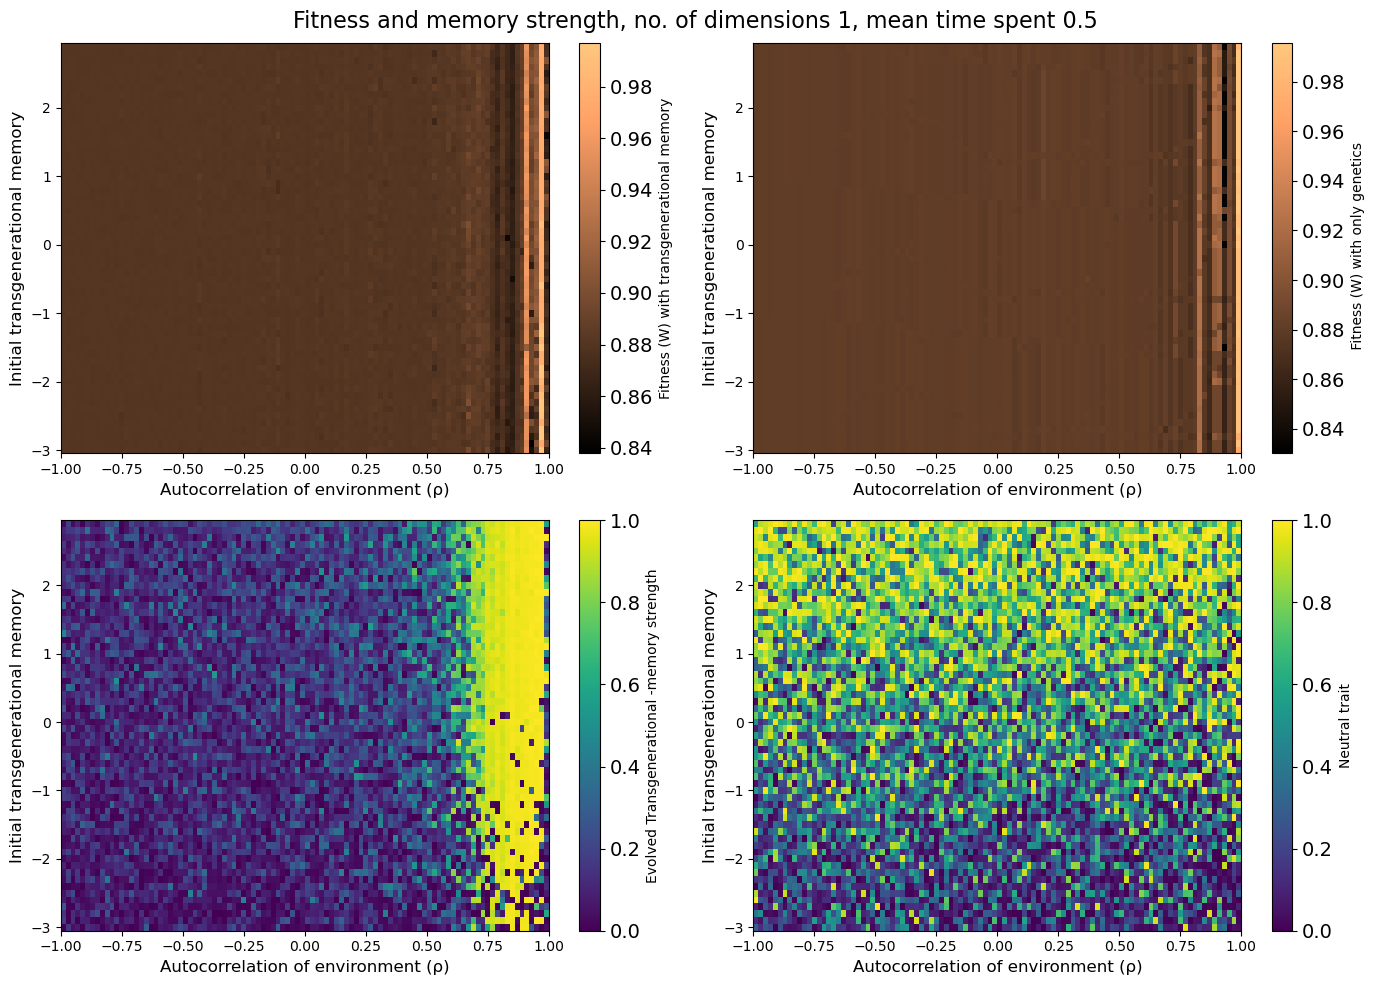

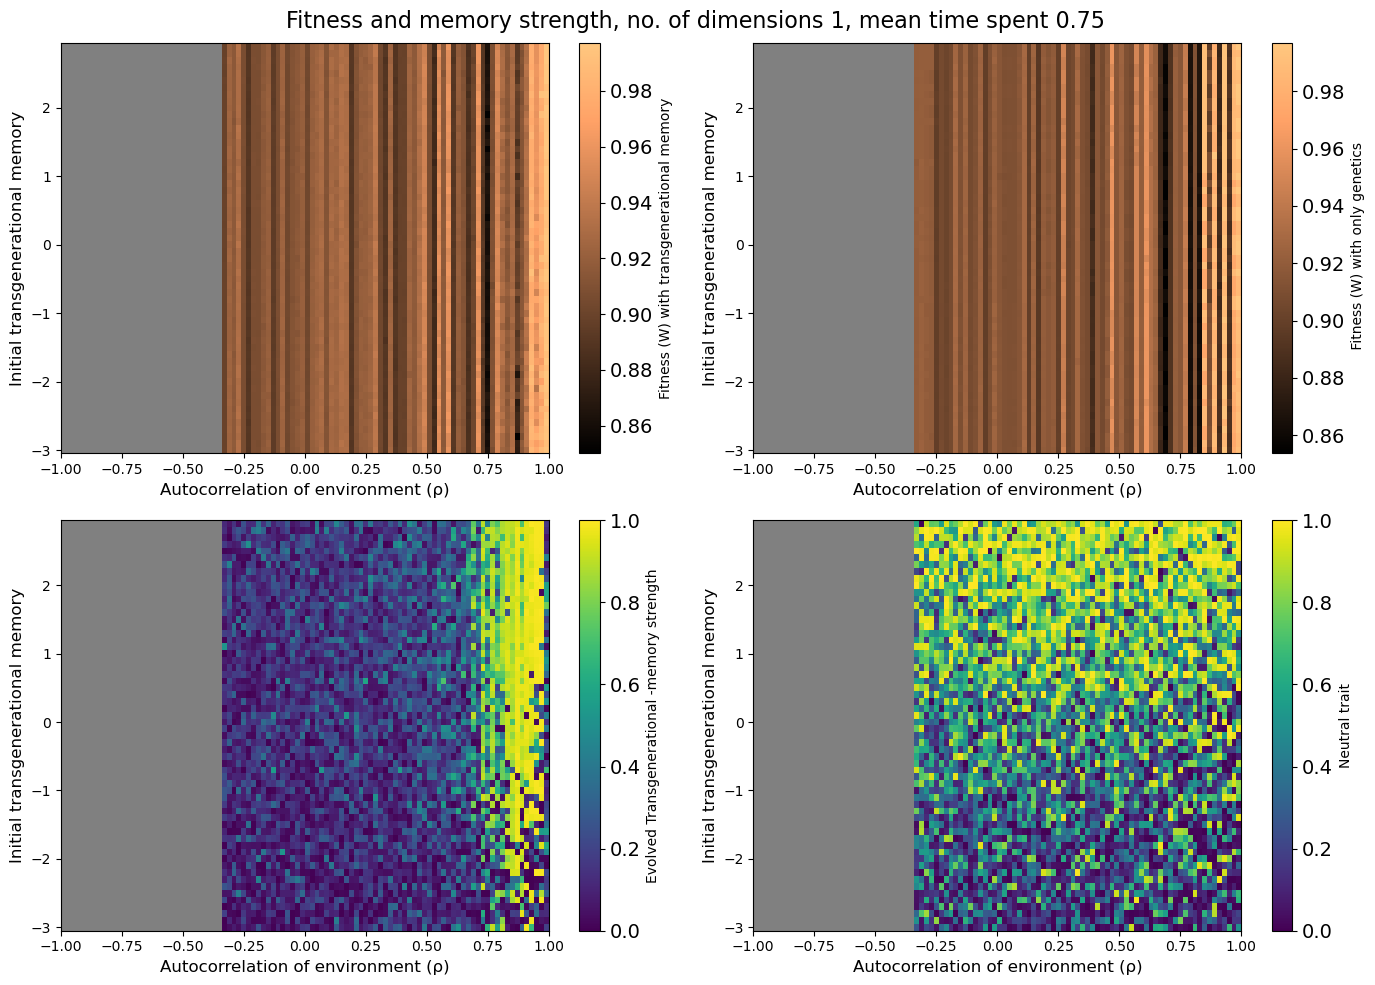

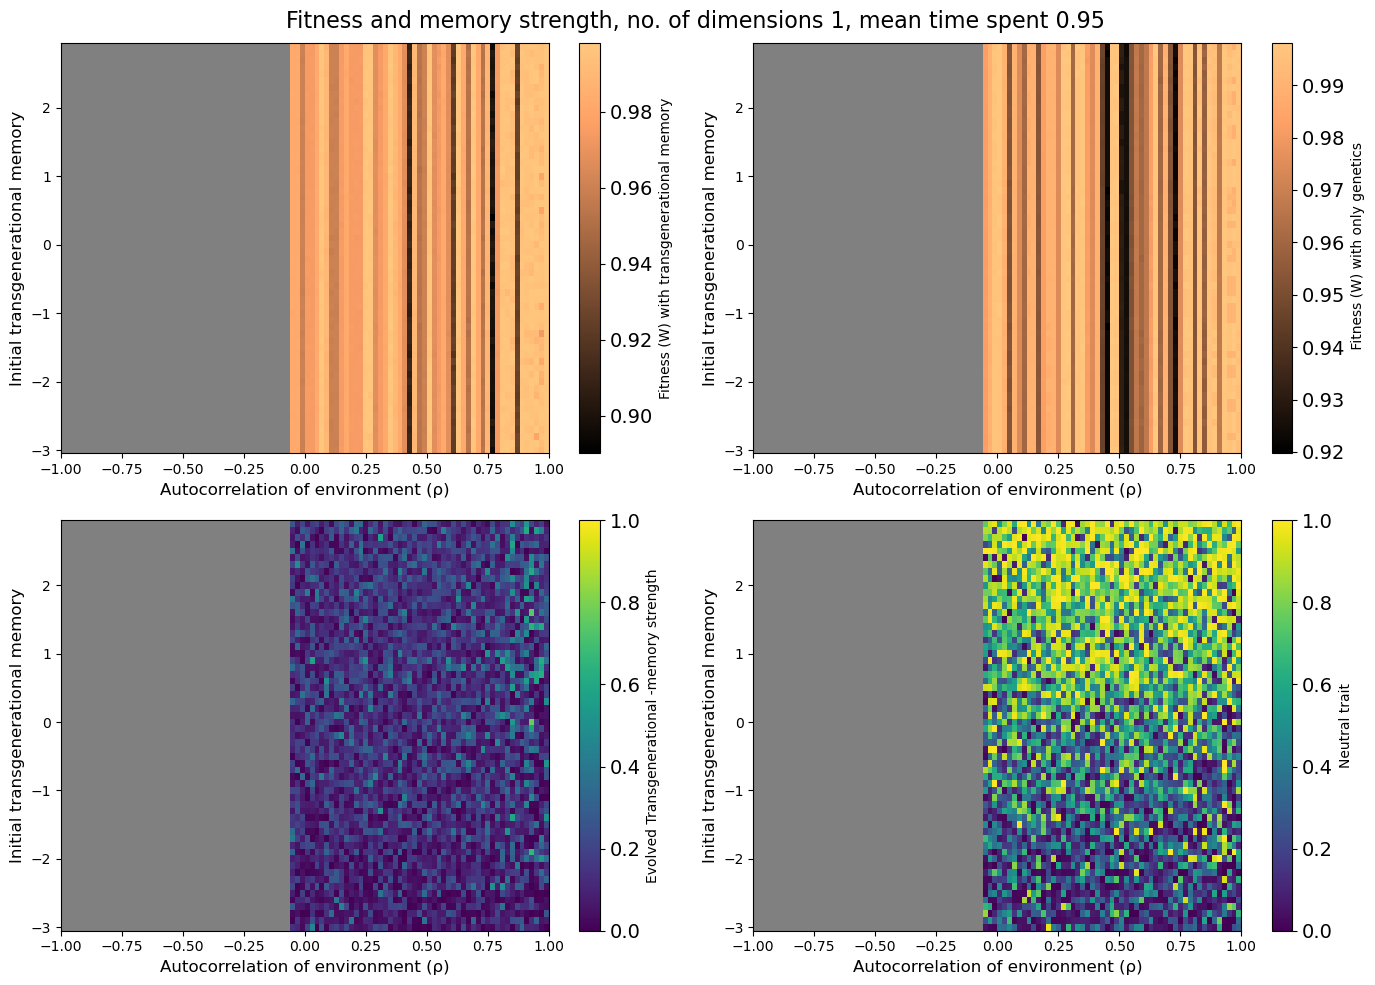

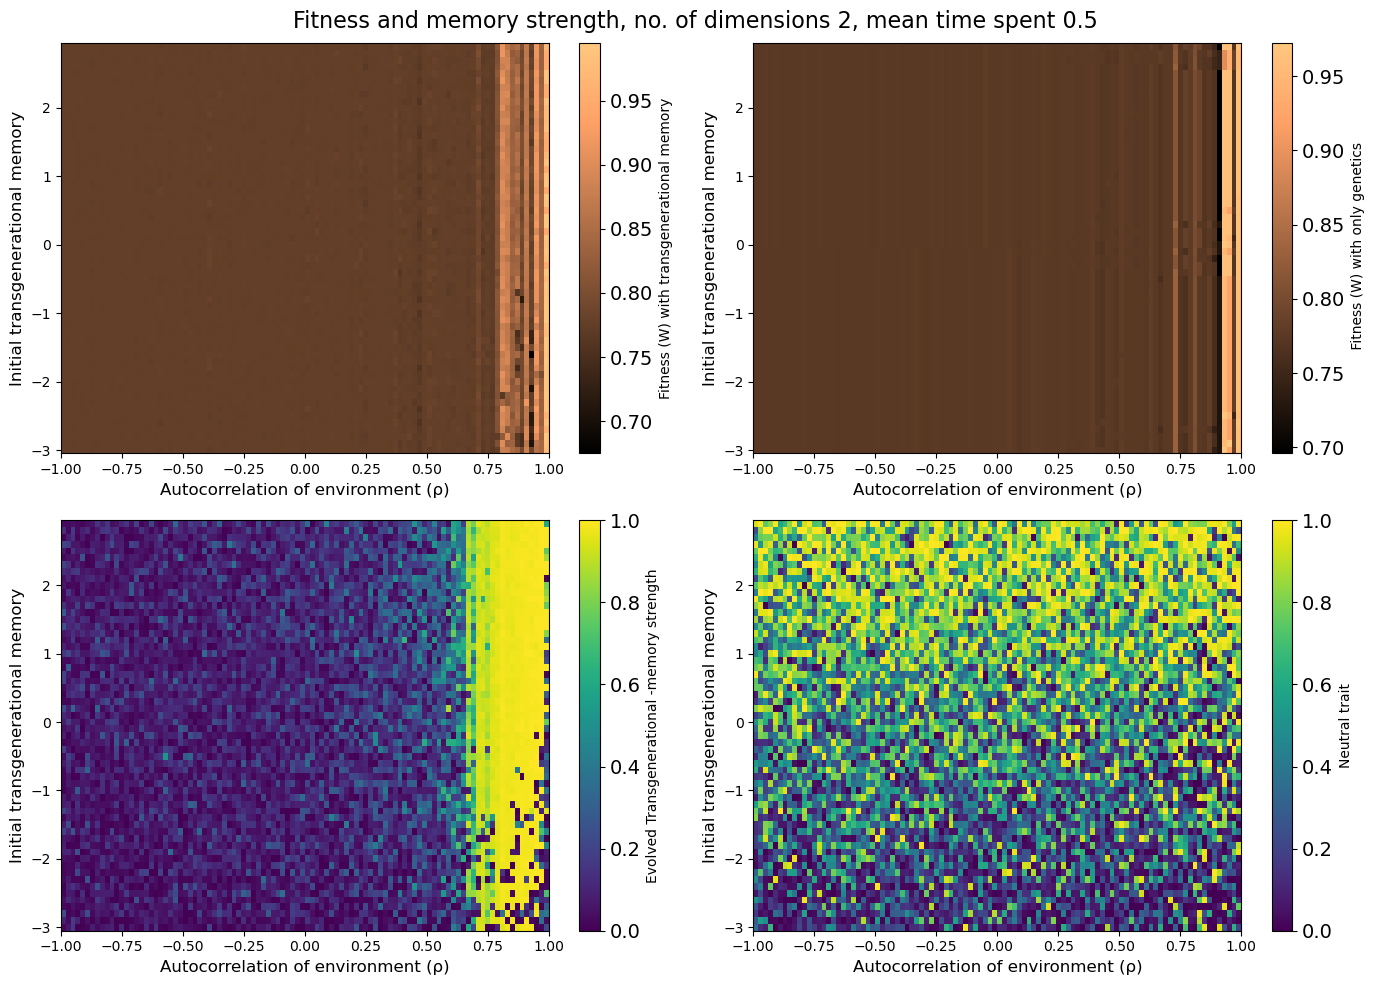

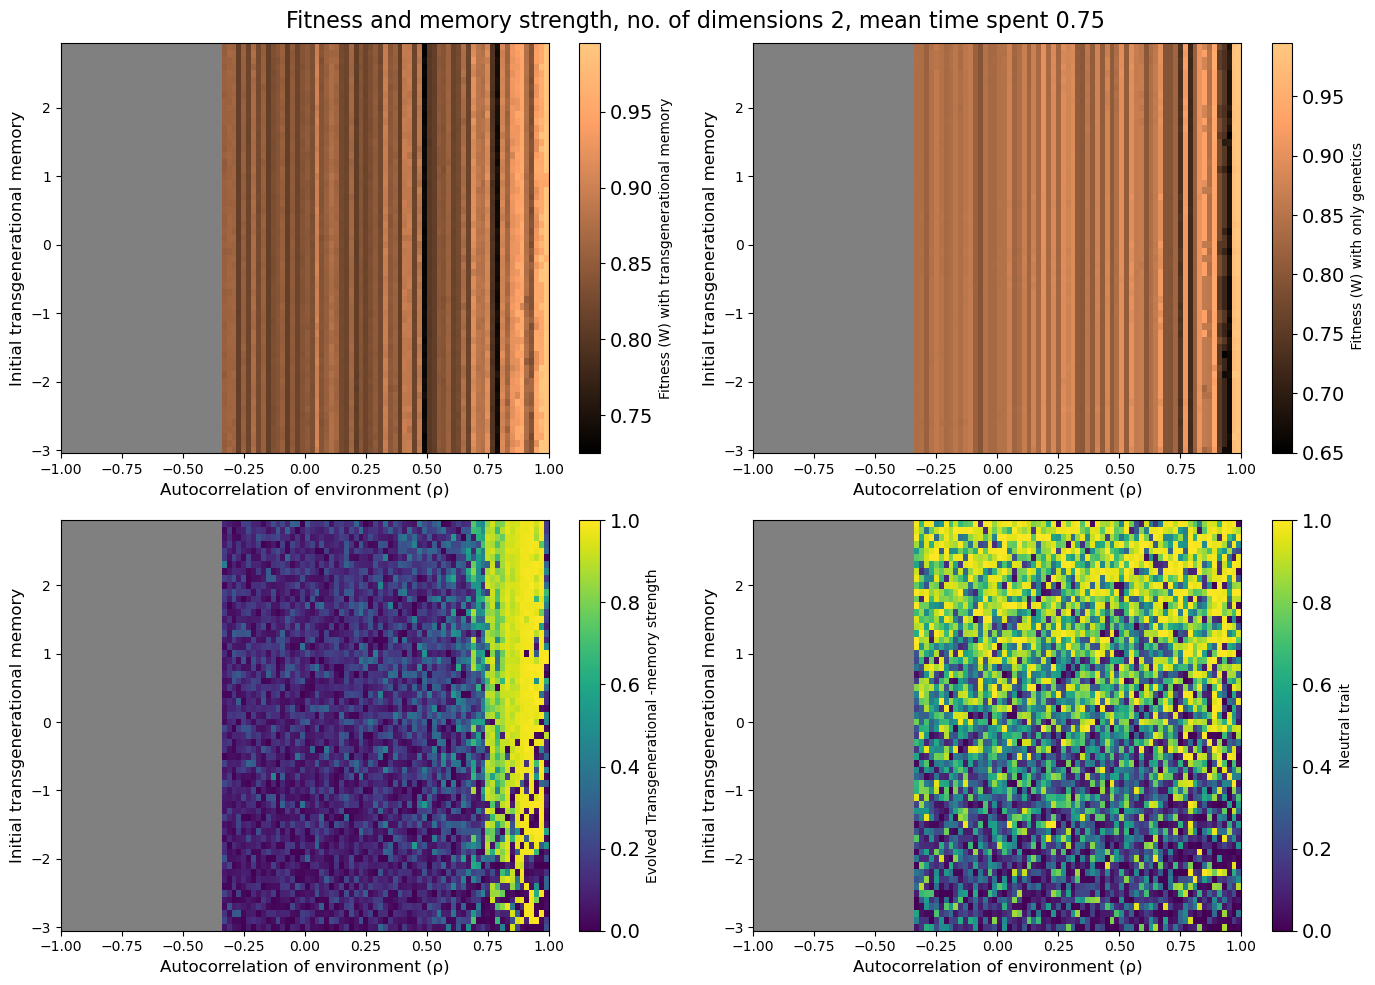

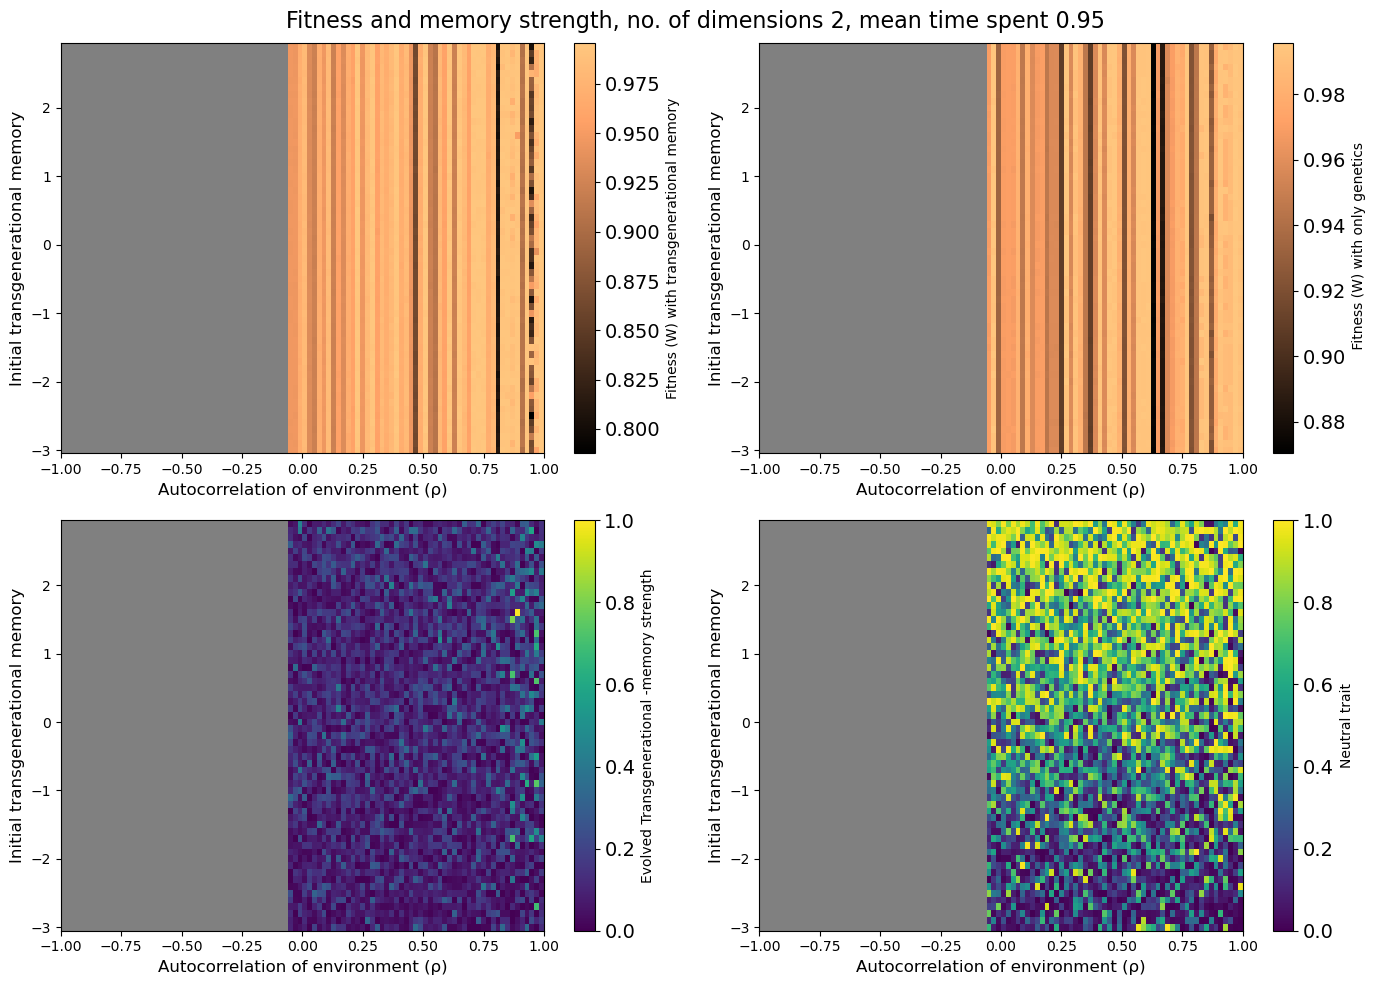

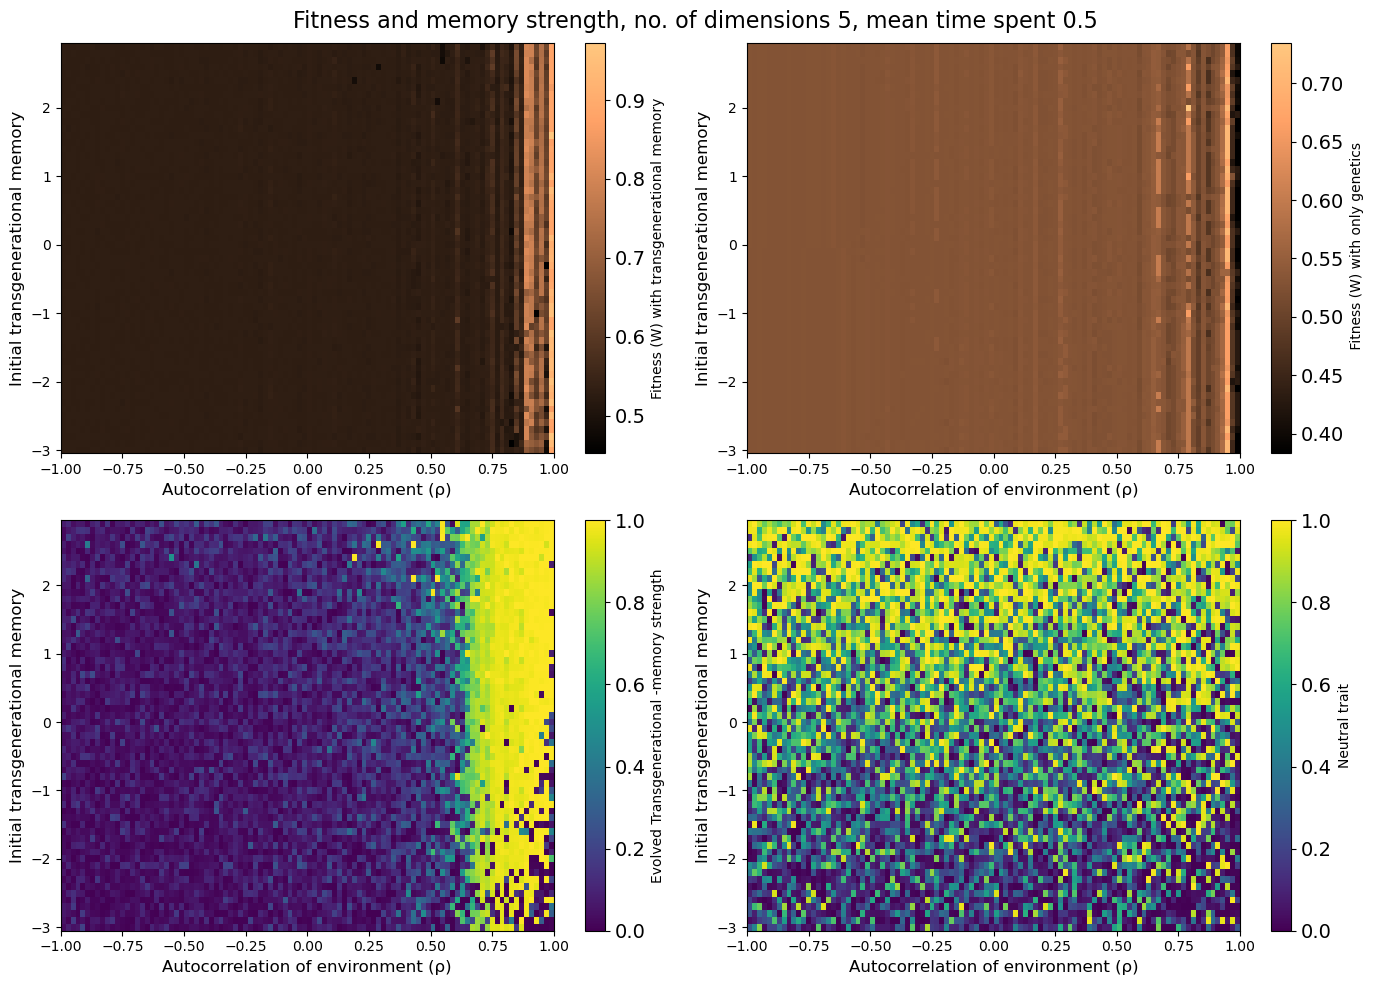

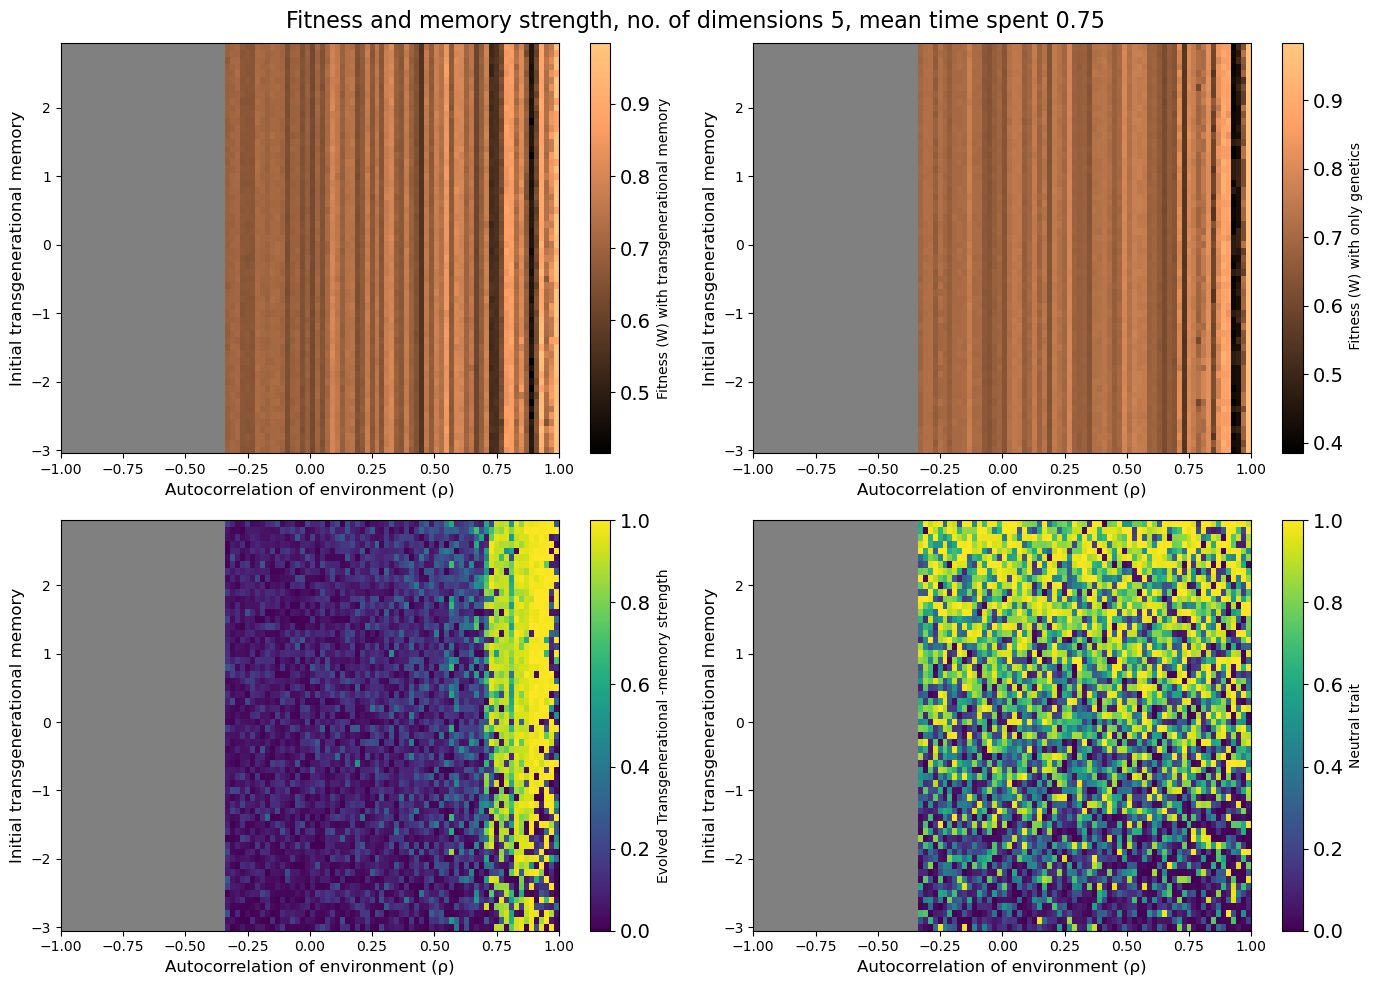

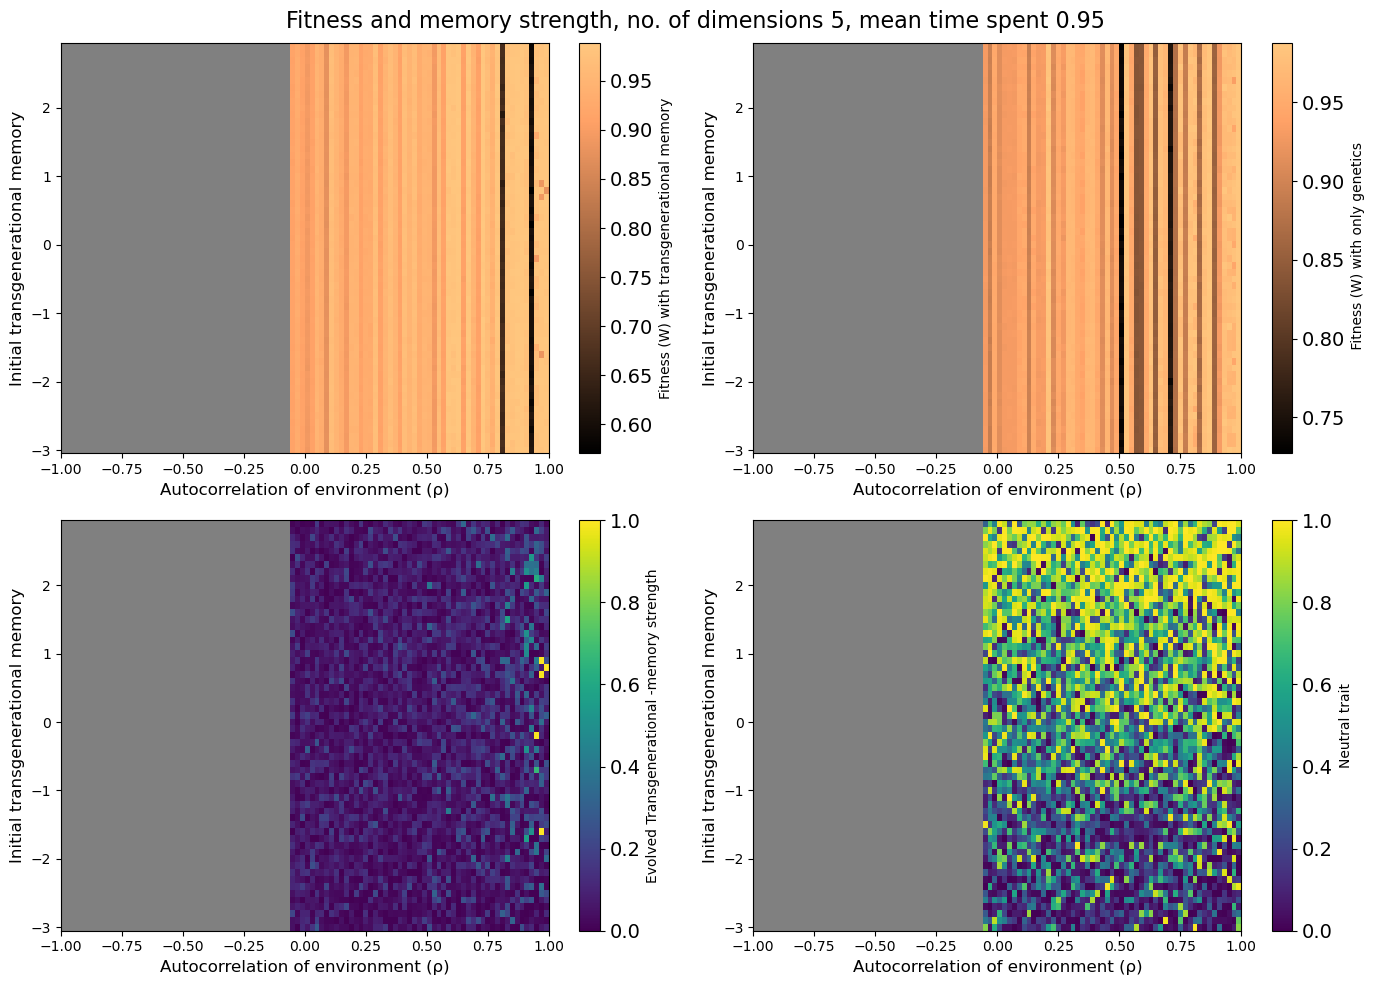

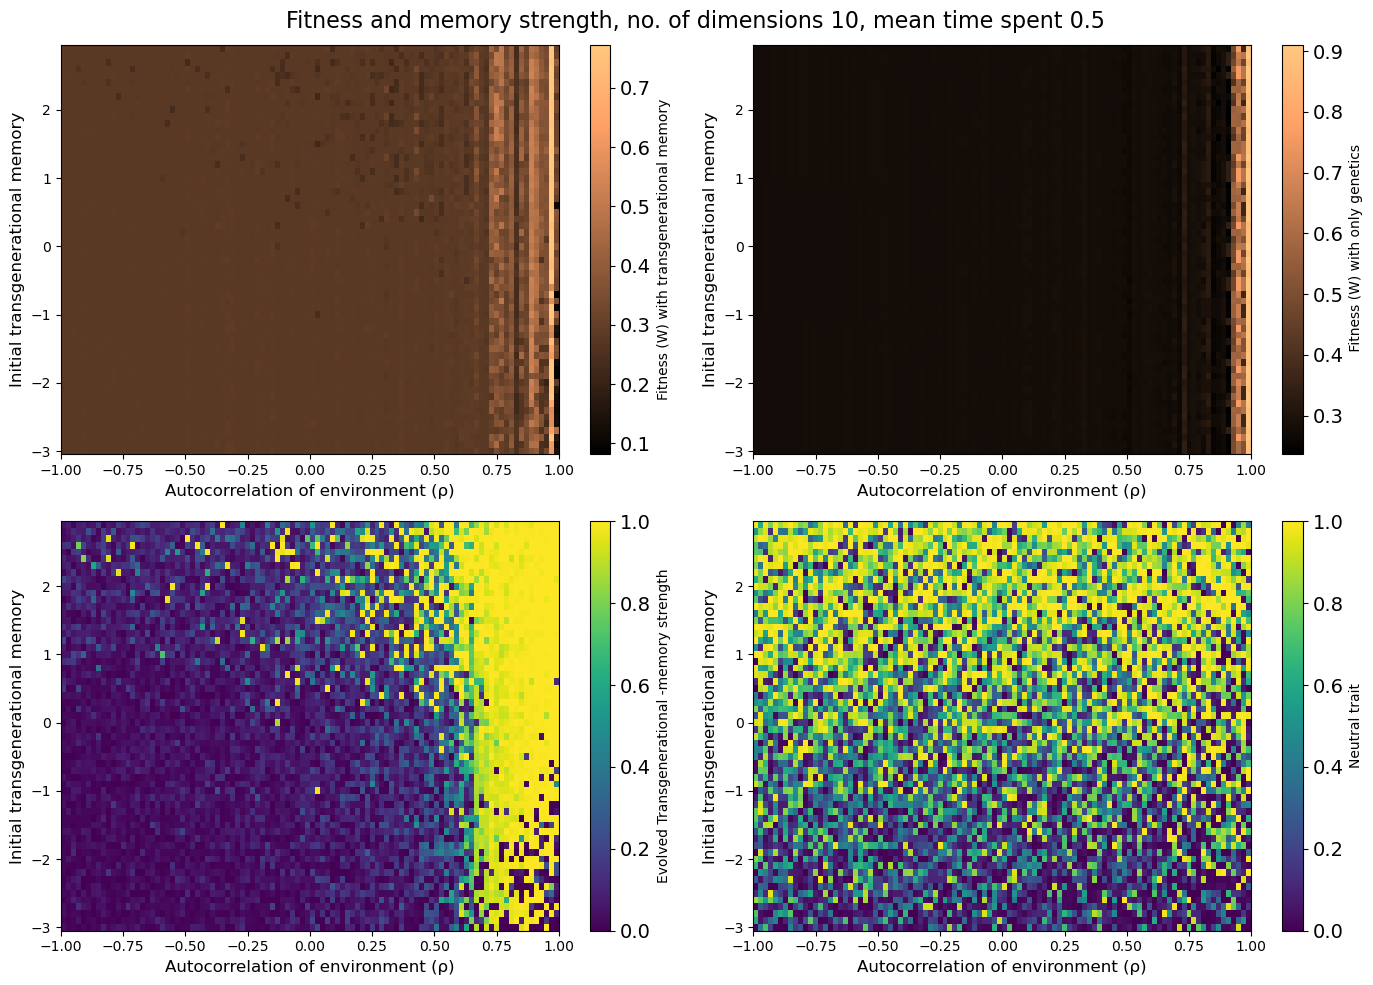

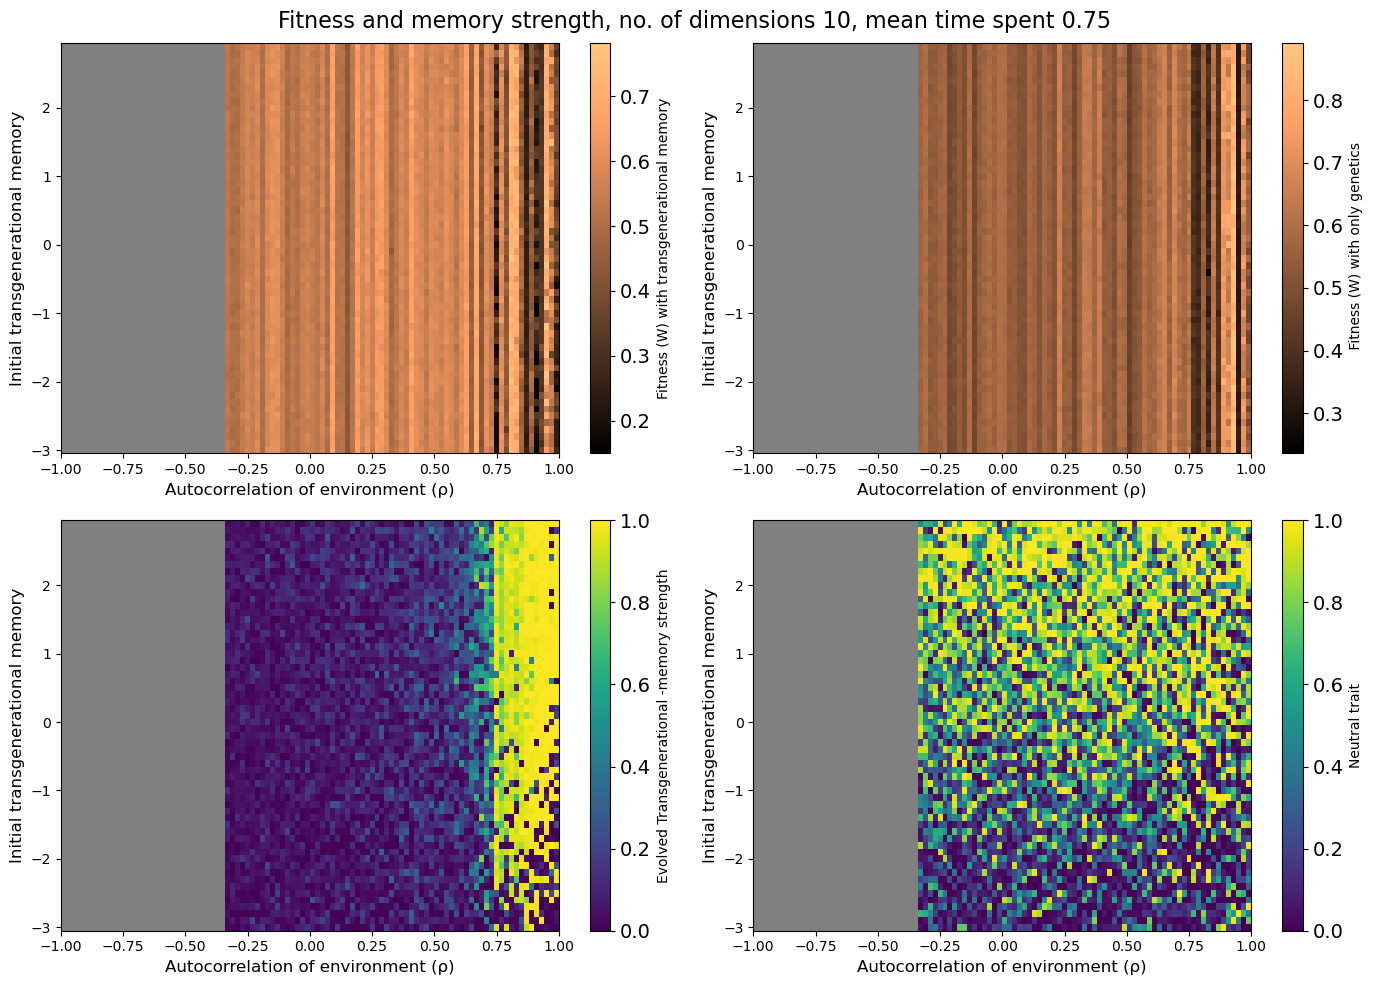

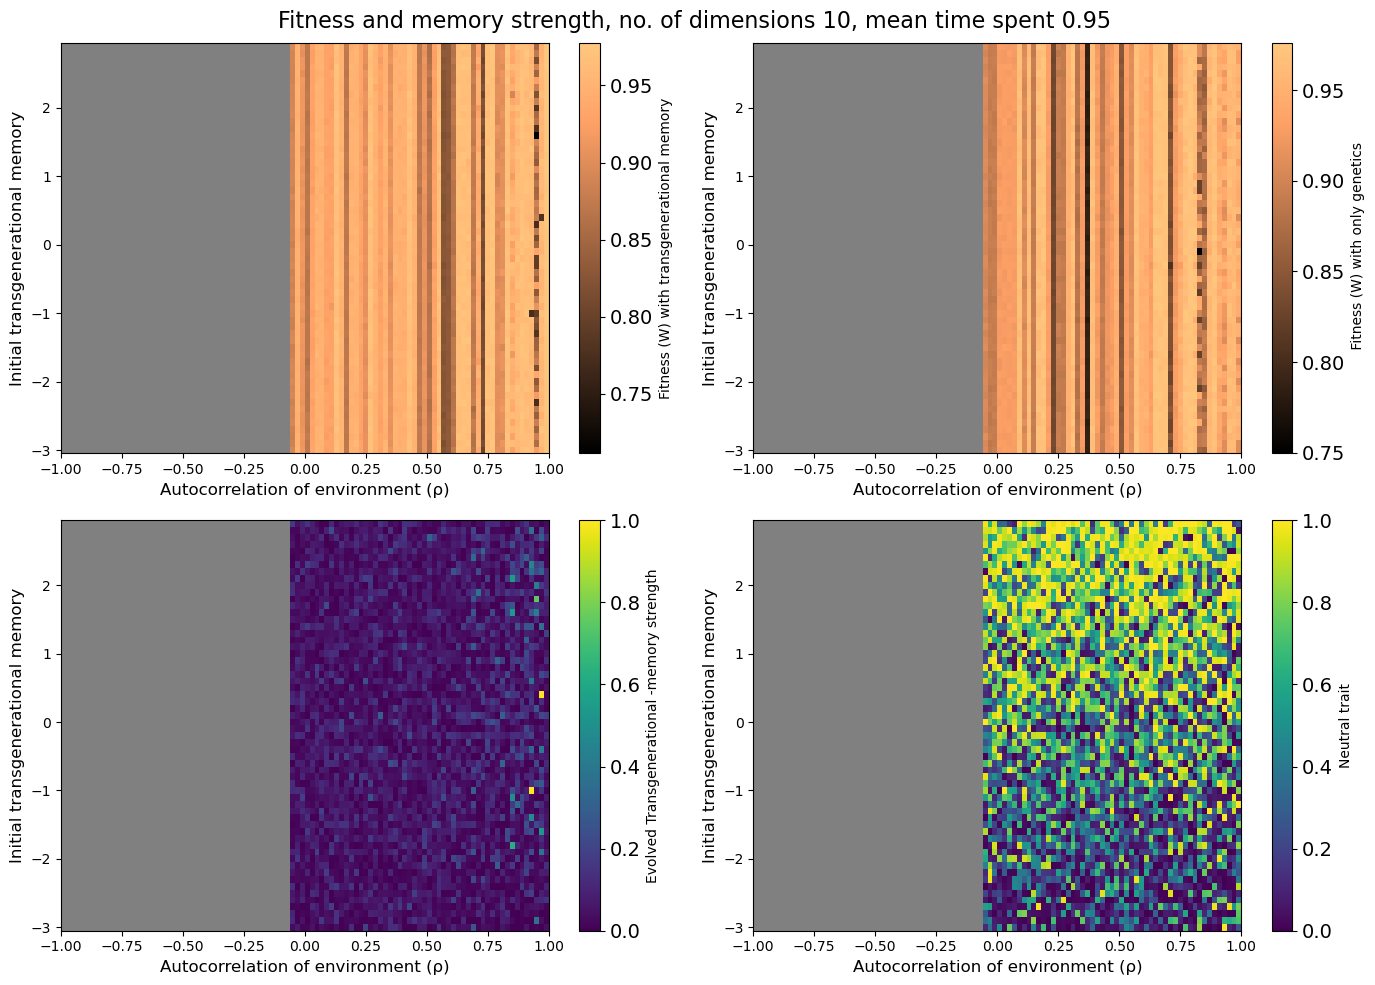

In [19]:
start =0

# Normalize rho range → [0, 1]

norm_rho = mcolors.Normalize(vmin=-1, vmax=1)
norm_m = mcolors.Normalize(vmin=0.5, vmax=1)
cmap_rho = cm.get_cmap("spring")
cmap_m = cm.get_cmap("cividis")

nof_dims =1
[]
# Create figure once (outside loop)
# Loop over scenarios
dimensions = ['dim_1','dim_2', 'dim_5','dim_10']

for dim in dimensions:
    
    nof_dims = "_".join(dim.split("_")[1:])
    
    data_subsetdim = sp_rho_data[dim]
    
    for m, group in data_subsetdim.groupby("ms"):

        
        fig, ax = plt.subplots(2, 2, figsize=(14, 10))
        fig.suptitle(f"Fitness and memory strength, no. of dimensions {nof_dims}, mean time spent {m}", fontsize=16)
        fig.subplots_adjust(top=0.90)   # more space for the suptitle
        cmap1 = plt.cm.copper.copy()  # copy to modify safely
        cmap1.set_bad(color='gray')    # gray for masked values
        
        
            
        cmap2 = plt.cm.viridis.copy()  # copy to modify safely
        cmap2.set_bad(color='gray')    # gray for masked values
        norm_c2= mcolors.Normalize(vmin=0, vmax=1)  # consistent color range
        
        data = pd.merge(
                scenarios,
                group,
                on=['rhos', 'initial_mem'],
                how='left')

        data['initial_mem_p'] = 1 / (1 + np.exp(-data['initial_mem']))
        
        # --- (0,0) fitness ---
        pivoted_fitness = data.pivot(
                index='initial_mem',
                columns='rhos',
                values='mean_last_50_epi_fitness'
            ).sort_index().sort_index(axis=1)
        
        max_abs = np.nanmax(np.abs(pivoted_fitness.values))
        min_abs = np.nanmin(np.abs(pivoted_fitness.values))
        norm = mcolors.Normalize(vmin=min_abs, vmax=max_abs)  # consistent color range
        
        pcm1 = ax[0,0].pcolormesh(
                pivoted_fitness.columns,
                pivoted_fitness.index,
                pivoted_fitness.values,
                cmap=cmap1,
                norm=norm,
                shading='auto'
            )
        cbar1 = fig.colorbar(pcm1, ax=ax[0,0], label='Fitness (W) with transgenerational memory'
                               )
        cbar1.ax.tick_params(labelsize=14)

        ax[0,0].set_ylabel('mean time spent in environment A (m)', fontsize=12)
        #ax[0,0].set_xlim(0,1)
        ax[0,0].set_ylabel('Initial transgenerational memory', fontsize=12)
        ax[0,0].set_xlabel('Autocorrelation of environment (ρ)', fontsize=12)


            # --- (0,1) genetic fitness ---
        pivoted_gen = data.pivot(
                index='initial_mem',
                columns='rhos',
                values='mean_last_50_genetic_fitness'
            ).sort_index().sort_index(axis=1)
        
        max_abs = np.nanmax(np.abs(pivoted_gen.values))
        min_abs = np.nanmin(np.abs(pivoted_gen.values))
        norm = mcolors.Normalize(vmin=min_abs, vmax=max_abs)  # consistent color range
        
        pcm2 = ax[0,1].pcolormesh(
                pivoted_gen.columns,
                pivoted_gen.index,
                pivoted_gen.values,
                cmap=cmap1,
                norm=norm,
                shading='auto'
            )
        cbar2 = fig.colorbar(pcm2, ax=ax[0,1], 
                                label=' Fitness (W) with only genetics'
                               )
        cbar2.ax.tick_params(labelsize=14)

        ax[0,1].set_ylabel('mean time spent in environment A (m)', fontsize=12)
        #ax[0,1].set_xlim(0,1)
        ax[0,1].set_ylabel('Initial transgenerational memory', fontsize=12)
        ax[0,1].set_xlabel('Autocorrelation of environment (ρ)', fontsize=12)

            # --- (1,0) epimem ---
        pivoted_epi = data.pivot(
                index='initial_mem',
                columns='rhos',
                values='mean_last_50_mean_memory'
            ).sort_index().sort_index(axis=1)
         
        pcm3 = ax[1,0].pcolormesh(
                pivoted_epi.columns,
                pivoted_epi.index,
                pivoted_epi.values,
                cmap=cmap2,
                norm=norm_c2,
                shading='auto'
            )
        cbar3 = fig.colorbar(pcm3, ax=ax[1,0], label=r'Evolved Transgenerational -memory strength'
                               )
        cbar3.ax.tick_params(labelsize=14)

        ax[1,0].set_ylabel('mean time spent in environment A (m)', fontsize=12)
        #ax[1,0].set_xlim(0,1)
        ax[1,0].set_ylabel('Initial transgenerational memory', fontsize=12)
        ax[1,0].set_xlabel('Autocorrelation of environment (ρ)', fontsize=12)

            # --- (1,1) neutral ---
        pivoted_neutral = data.pivot(
                index='initial_mem',
                columns='rhos',
                values='mean_last_50_mean_neutral'
            ).sort_index().sort_index(axis=1)

        pcm4 = ax[1,1].pcolormesh(
                pivoted_neutral.columns,
                pivoted_neutral.index,
                pivoted_neutral.values,
                cmap=cmap2,
                norm=norm_c2,
                shading='auto'
            )
        cbar4 = fig.colorbar(pcm4, ax=ax[1,1], label='Neutral trait'
                                )
        cbar4.ax.tick_params(labelsize=14)

        ax[1,1].set_ylabel('mean time spent in environment A (m)', fontsize=12)
        #ax[1,1].set_xlim(0,1)
        ax[1,1].set_ylabel('Initial transgenerational memory', fontsize=12)
        ax[1,1].set_xlabel('Autocorrelation of environment (ρ)', fontsize=12)
                
                
        plt.tight_layout()
        plt.savefig(f'/home/usriniva/Desktop/Phd/Epigenetics/Simulations/New_Hanna_eqns/Evolve_Transgenerational_memory/Figures/finegrain_sp/Finegrain_sp_{dim}')
        plt.show()
            
        

#### Above heatmaps; coloured by distance from initial transgenerational memory/ neutral trait

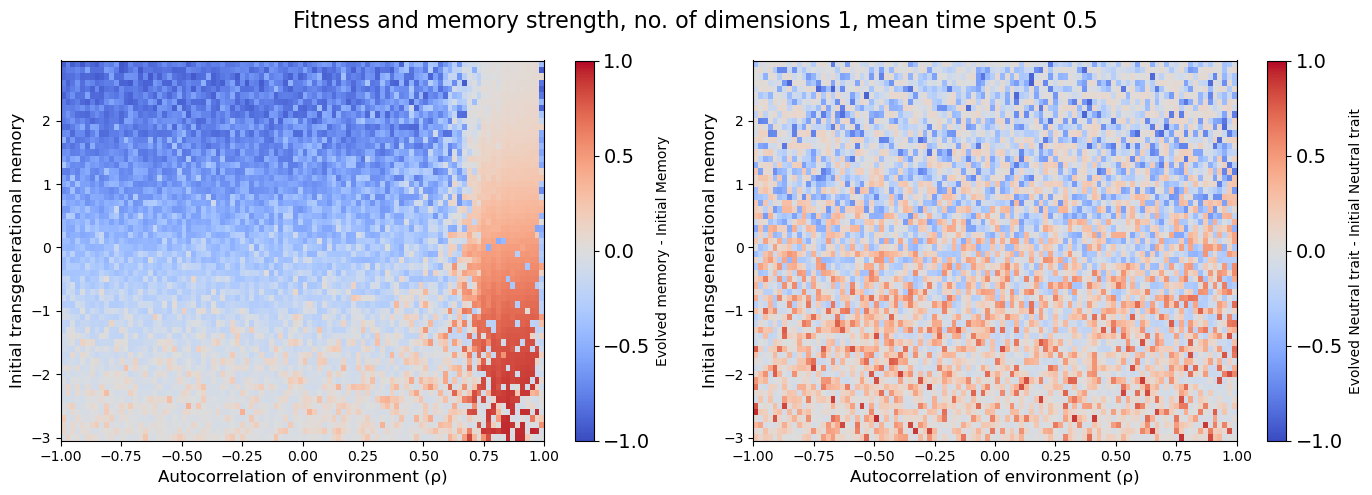

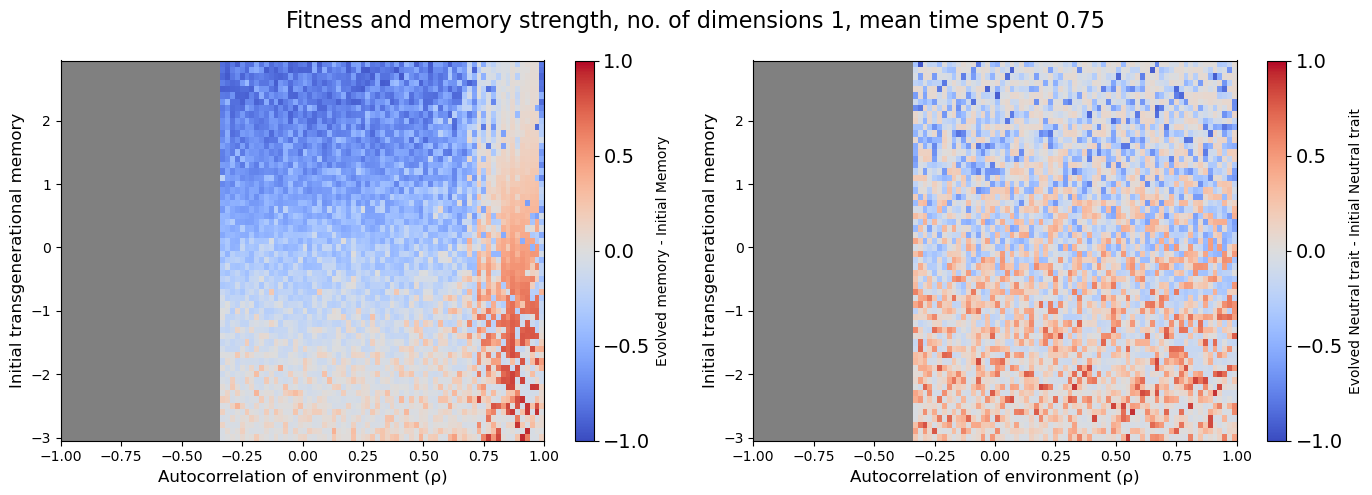

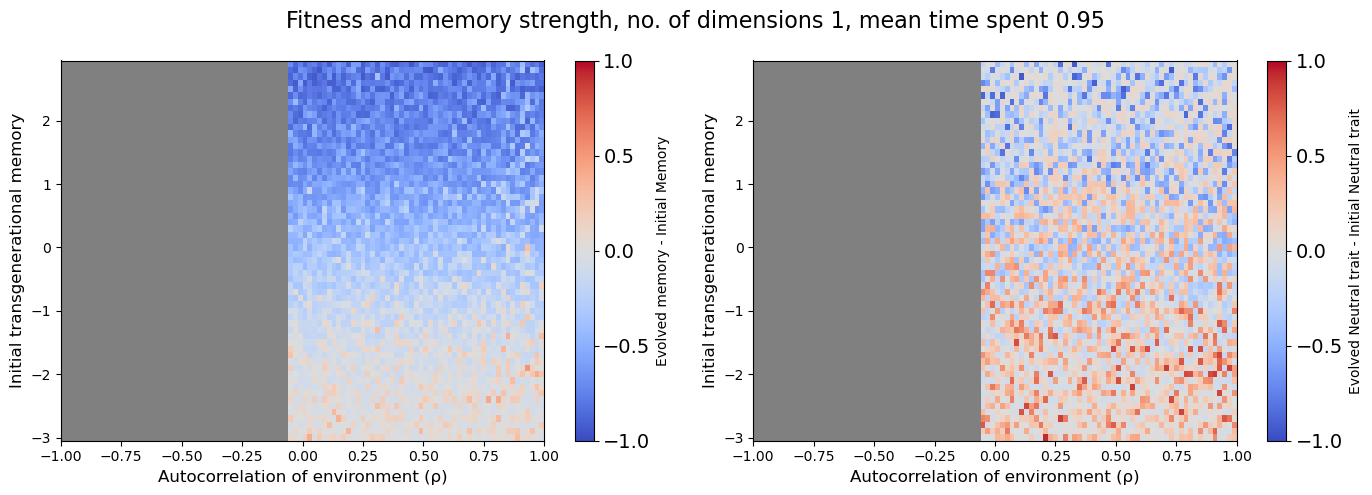

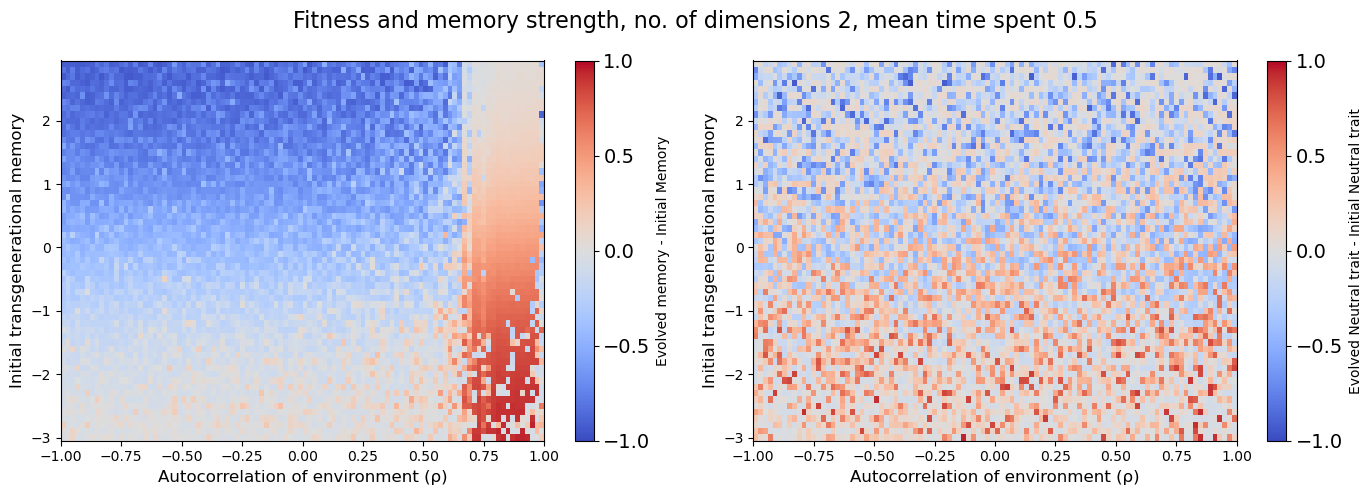

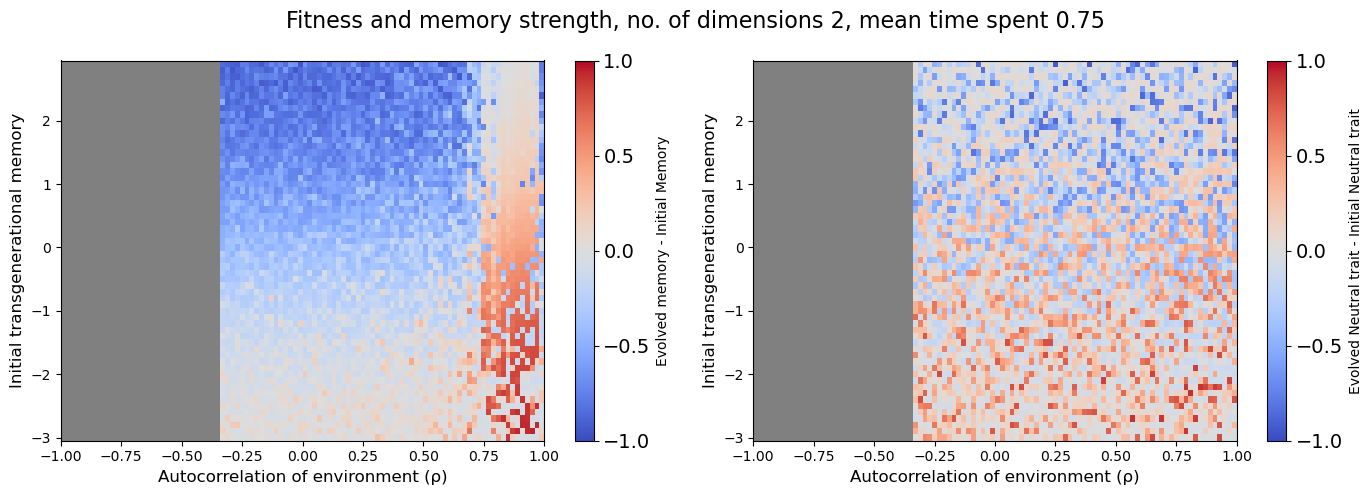

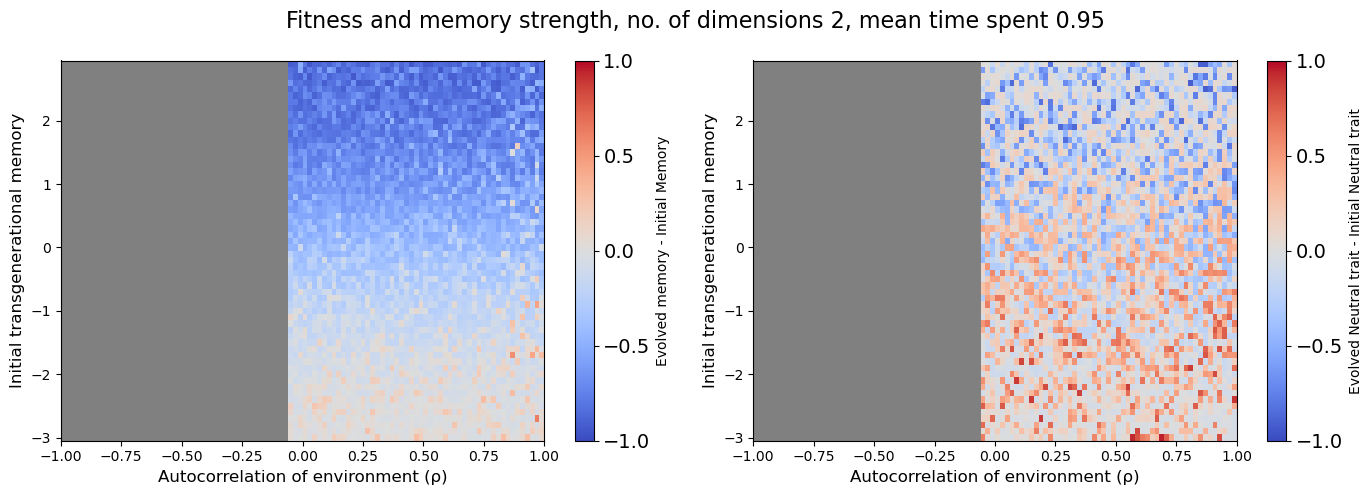

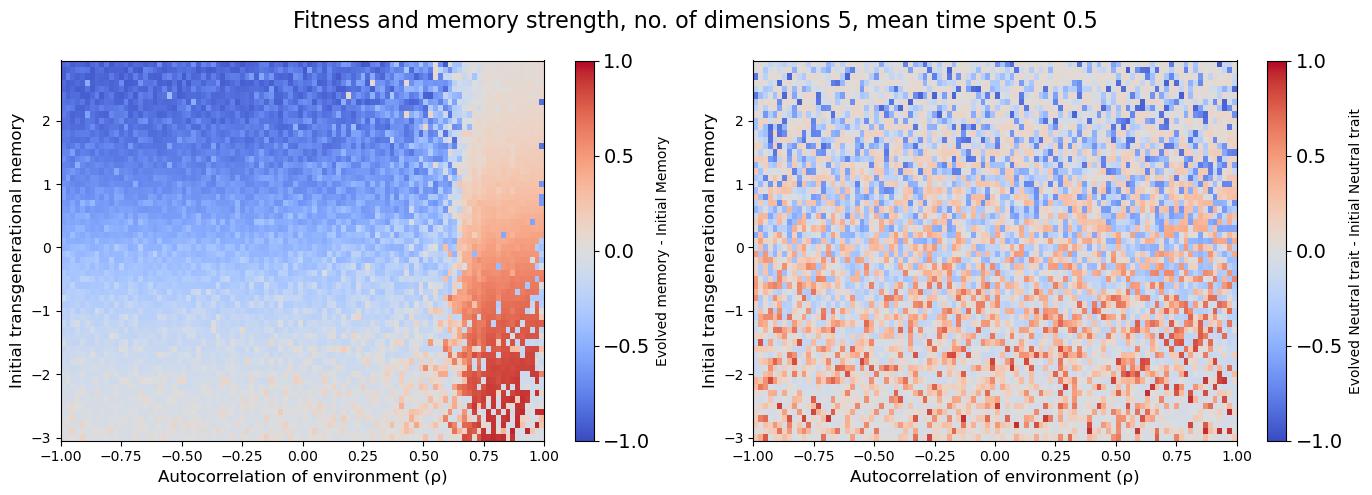

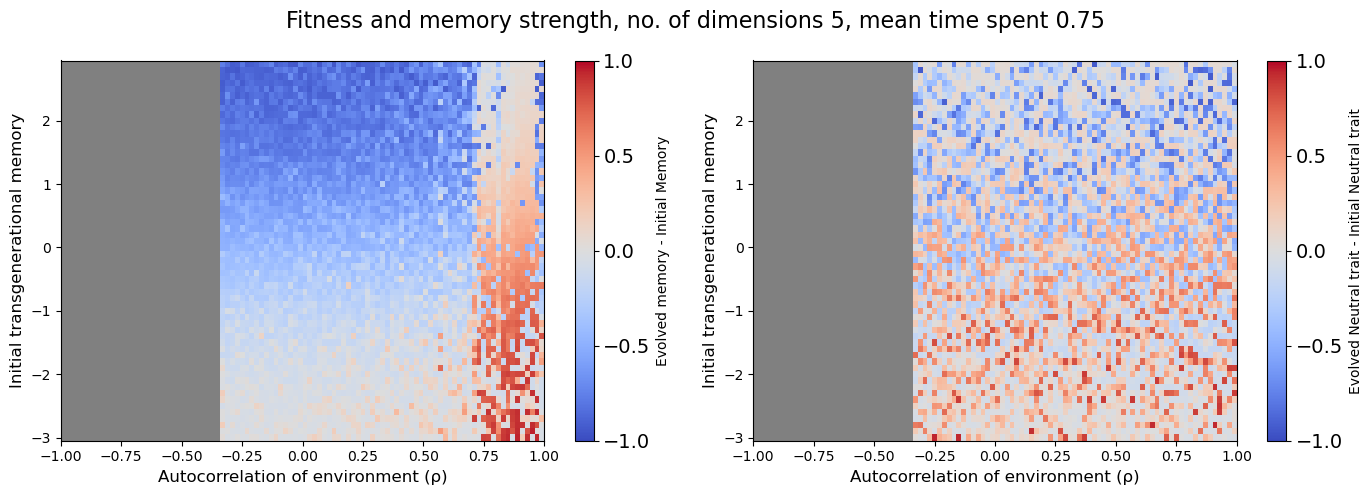

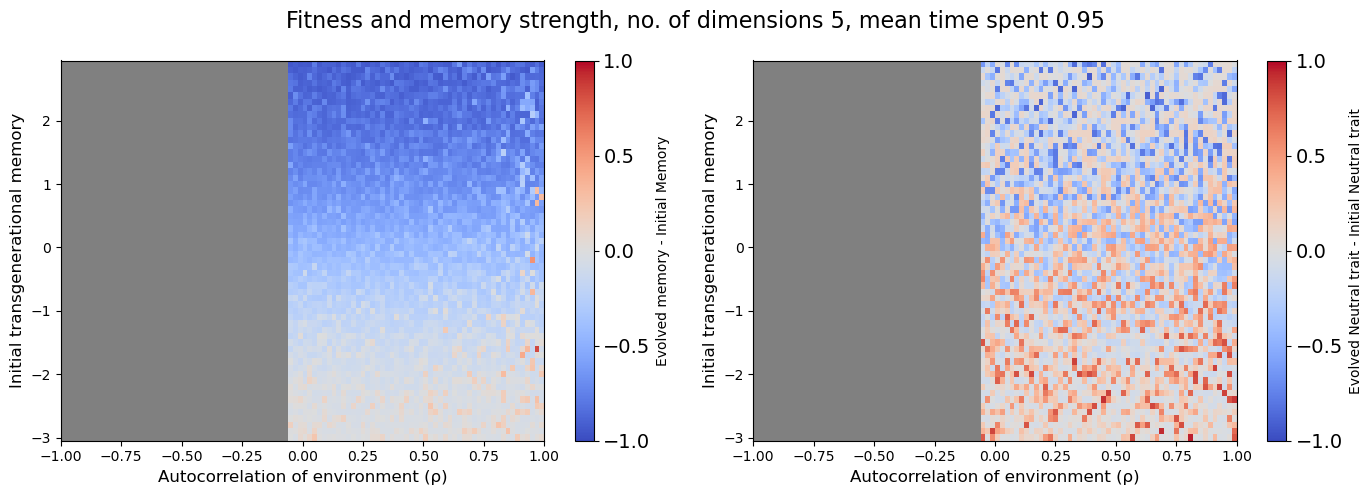

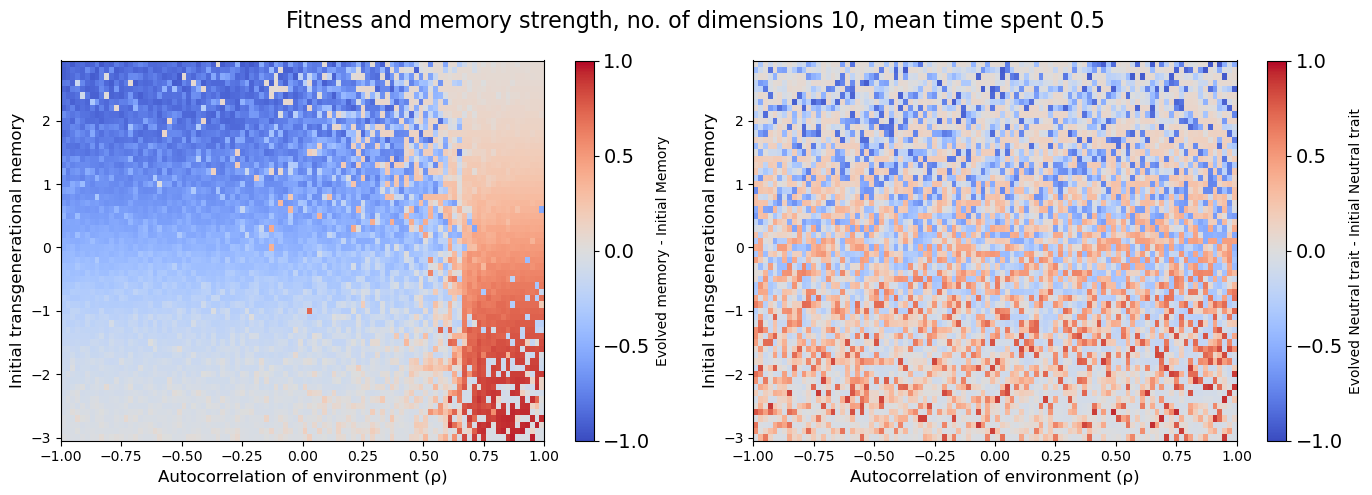

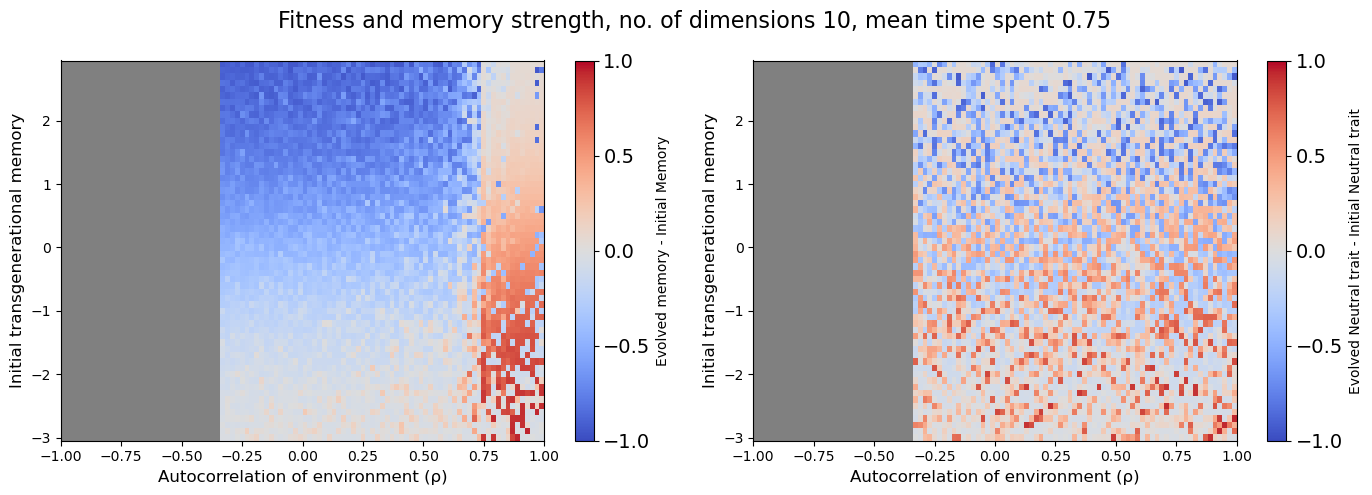

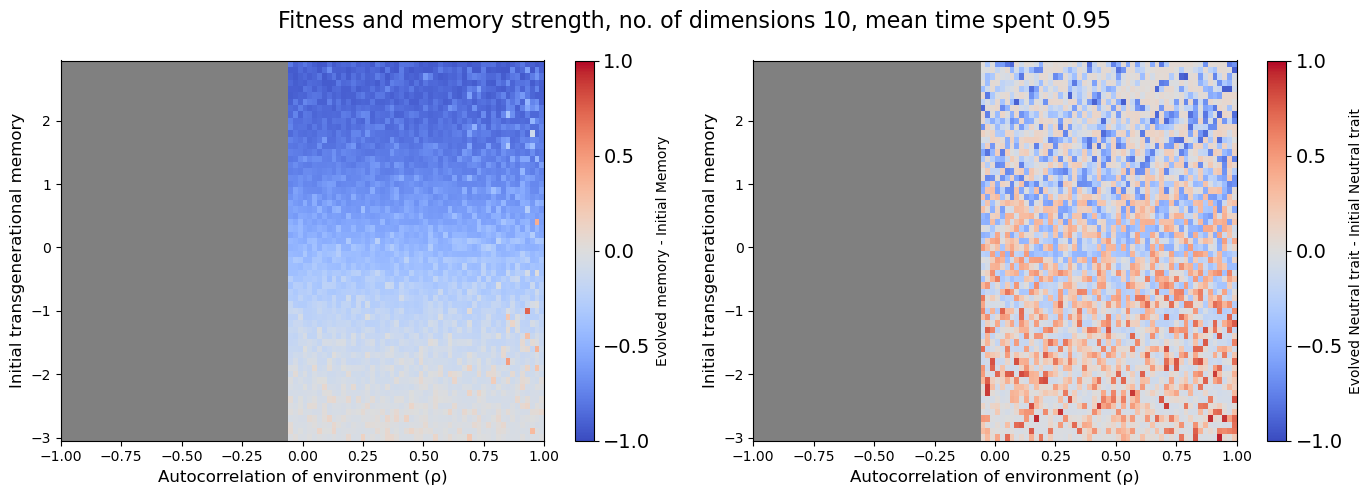

In [20]:
start =0

# Normalize rho range → [0, 1]


nof_dims =1

# Create figure once (outside loop)
# Loop over scenarios
for dim in dimensions:
    
    nof_dims = "_".join(dim.split("_")[1:])
    
    data_subsetdim = sp_rho_data[dim]
    
    
    for m, group in data_subsetdim.groupby("ms"):

        
        fig, ax = plt.subplots(1, 2, figsize=(14, 5))
        fig.suptitle(f"Fitness and memory strength, no. of dimensions {nof_dims}, mean time spent {m}", fontsize=16)
        fig.subplots_adjust(top=0.90)   # more space for the suptitle
        
        
        # colormap for difference
        cmap = plt.cm.coolwarm.copy()
        cmap.set_bad(color='gray')

        # symmetric normalization around 0
        norm_diff = mcolors.TwoSlopeNorm(vmin=-1, vcenter=0.0, vmax=1)
        
        data = pd.merge(
                scenarios,
                group,
                on=['rhos', 'initial_mem'],
                how='left')
        
        data['initial_mem_p'] = 1 / (1 + np.exp(-data['initial_mem']))
        
        data['memory_difference'] = (data['mean_last_50_mean_memory']-
        data['initial_mem_p'])
        
        data['neutral_difference'] = (data['mean_last_50_mean_neutral'] - data['initial_mem_p'])
        
            # --- (1,0) epimem ---
        pivoted_epi = data.pivot(
                index='initial_mem',
                columns='rhos',
                values='memory_difference'
            ).sort_index().sort_index(axis=1)

        pcm3 = ax[0].pcolormesh(
                pivoted_epi.columns,
                pivoted_epi.index,
                pivoted_epi.values,
                cmap=cmap,
                norm=norm_diff,
                shading='auto'
            )
        cbar3 = fig.colorbar(pcm3, ax=ax[0], label=r'Evolved memory - Initial Memory',
                               ticks=[-1, -0.5, 0, 0.5, 1.0])
        cbar3.ax.tick_params(labelsize=14)

        ax[0].set_ylabel('mean time spent in environment A (m)', fontsize=12)
        #ax[1,0].set_xlim(0,1)
        ax[0].set_ylabel('Initial transgenerational memory', fontsize=12)
        ax[0].set_xlabel('Autocorrelation of environment (ρ)', fontsize=12)

            # --- (1,1) neutral ---
        pivoted_neutral = data.pivot(
                index='initial_mem',
                columns='rhos',
                values='neutral_difference'
            ).sort_index().sort_index(axis=1)

        pcm4 = ax[1].pcolormesh(
                pivoted_neutral.columns,
                pivoted_neutral.index,
                pivoted_neutral.values,
                cmap=cmap,
                norm=norm_diff,
                shading='auto'
            )
        cbar4 = fig.colorbar(pcm4, ax=ax[1], label='Evolved Neutral trait - Initial Neutral trait',
                                ticks=[-1, -0.5, 0, 0.5, 1.0])
        cbar4.ax.tick_params(labelsize=14)

        ax[1].set_ylabel('mean time spent in environment A (m)', fontsize=12)
        #ax[1,1].set_xlim(0,1)
        ax[1].set_ylabel('Initial transgenerational memory', fontsize=12)
        ax[1].set_xlabel('Autocorrelation of environment (ρ)', fontsize=12)
                
        folder = '/home/usriniva/Desktop/Phd/Epigenetics/Simulations/New_Hanna_eqns/Evolve_Transgenerational_memory/Figures/finegrain_sp'
        plt.tight_layout()
        plt.savefig(f'{folder}/memory_difference_from_starting point_{dim}')
        plt.show()
            
        

#### Difference between transgenerational memory and neutral trait; epigenetic fitness and genetic fitness

/tmp/ipykernel_5829/1973810567.py:5: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap_rho = cm.get_cmap("spring")
/tmp/ipykernel_5829/1973810567.py:6: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap_m = cm.get_cmap("cividis")


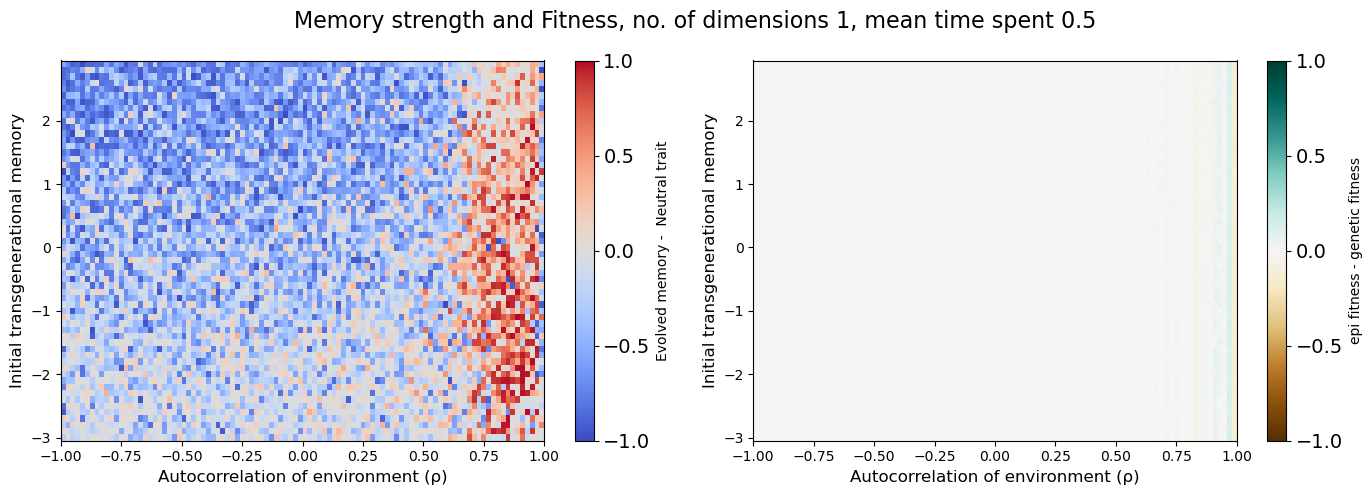

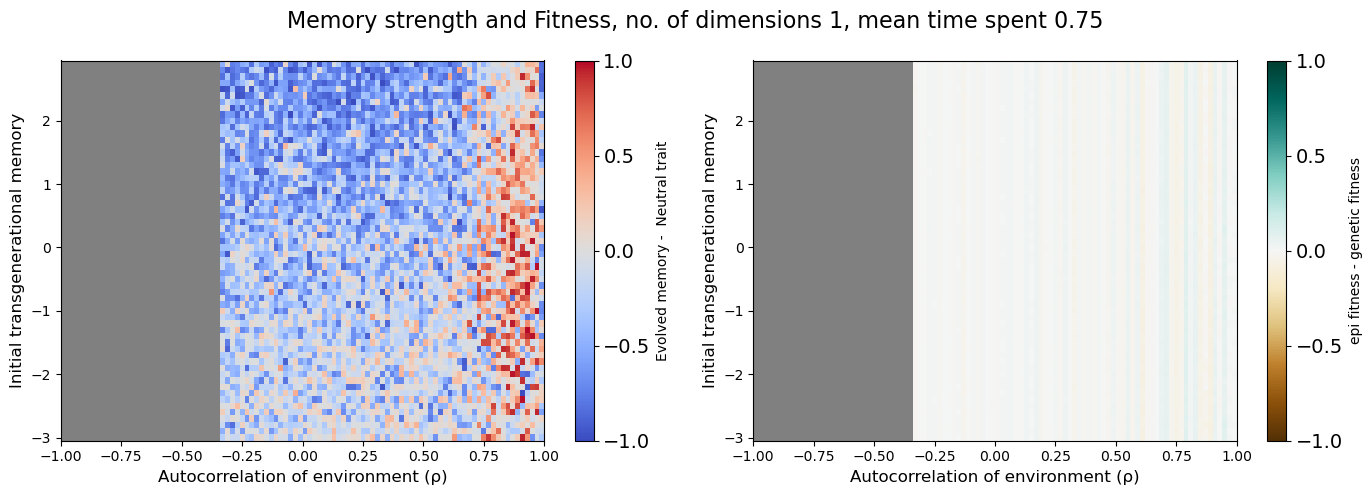

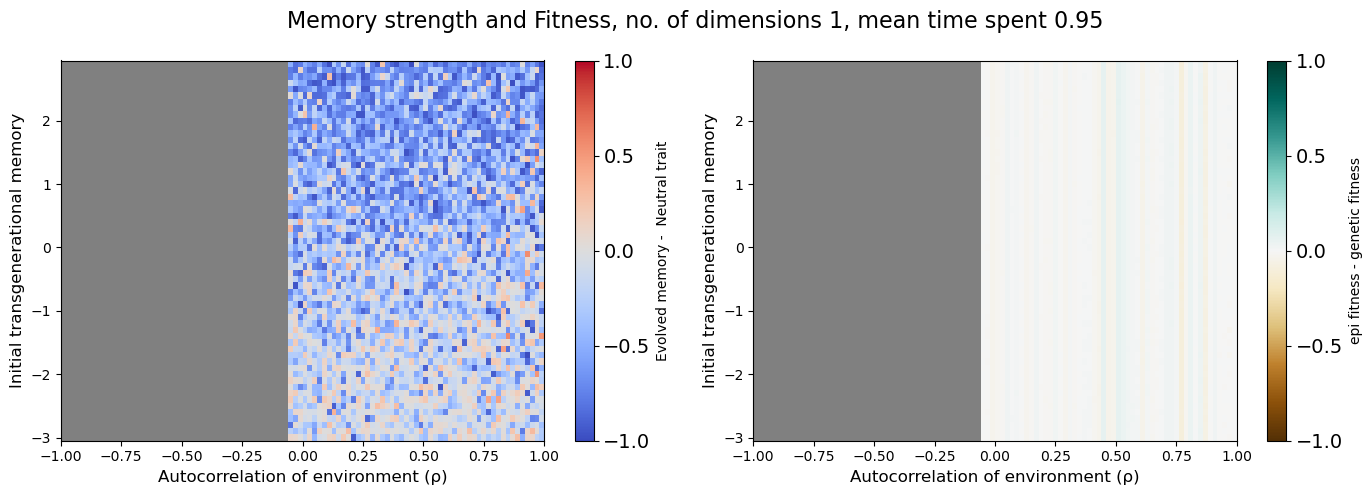

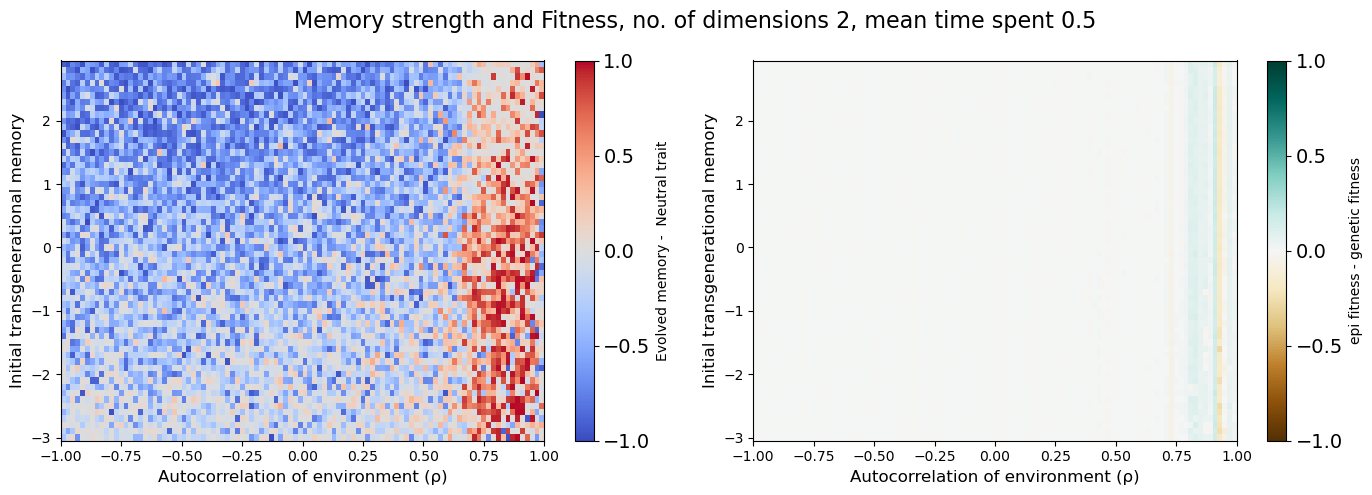

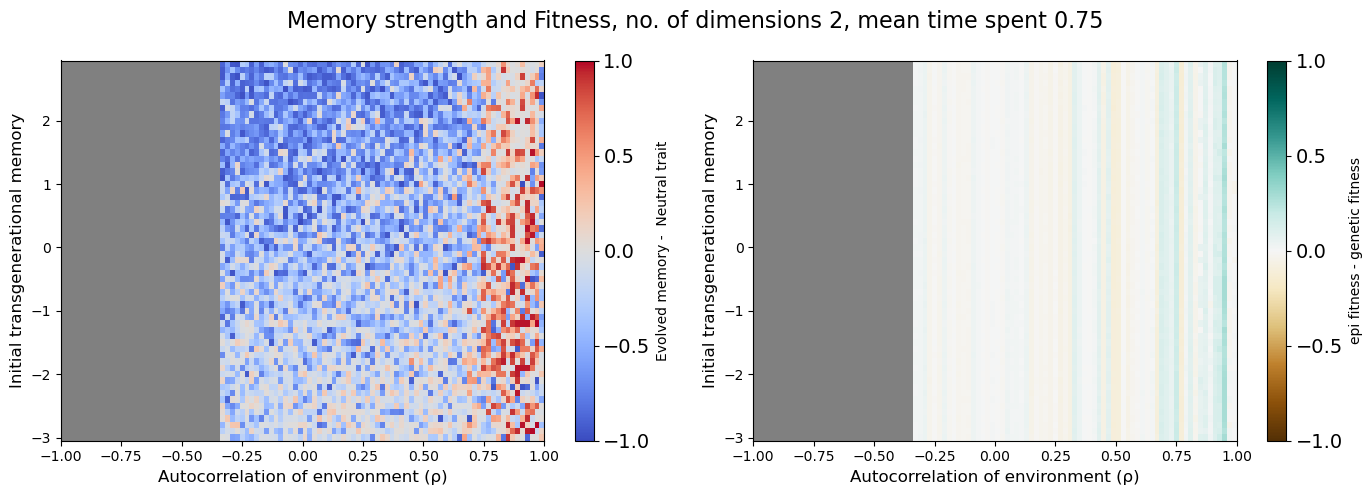

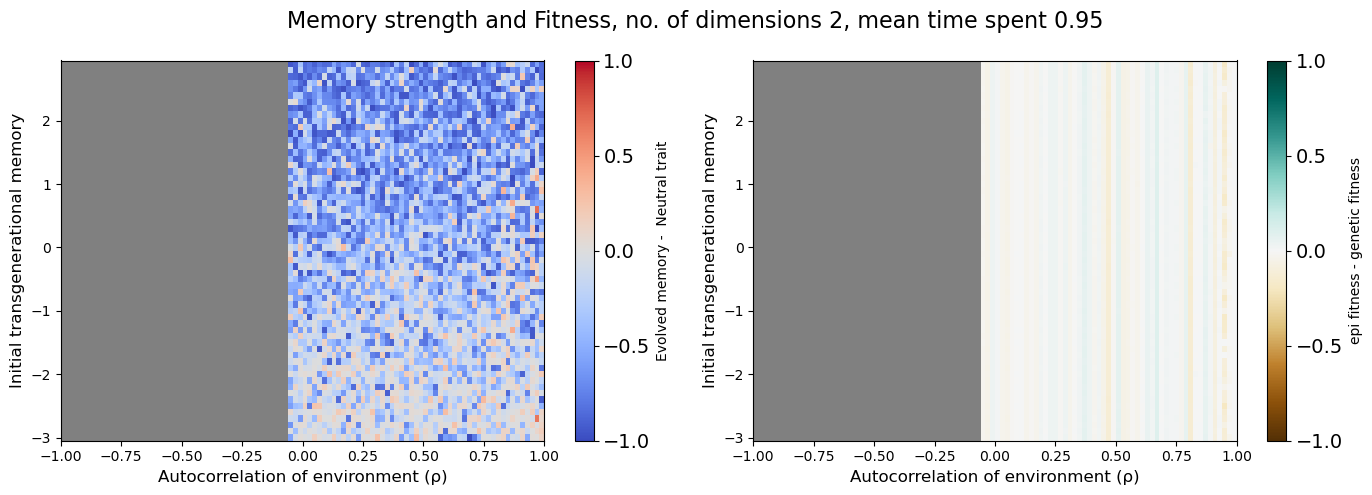

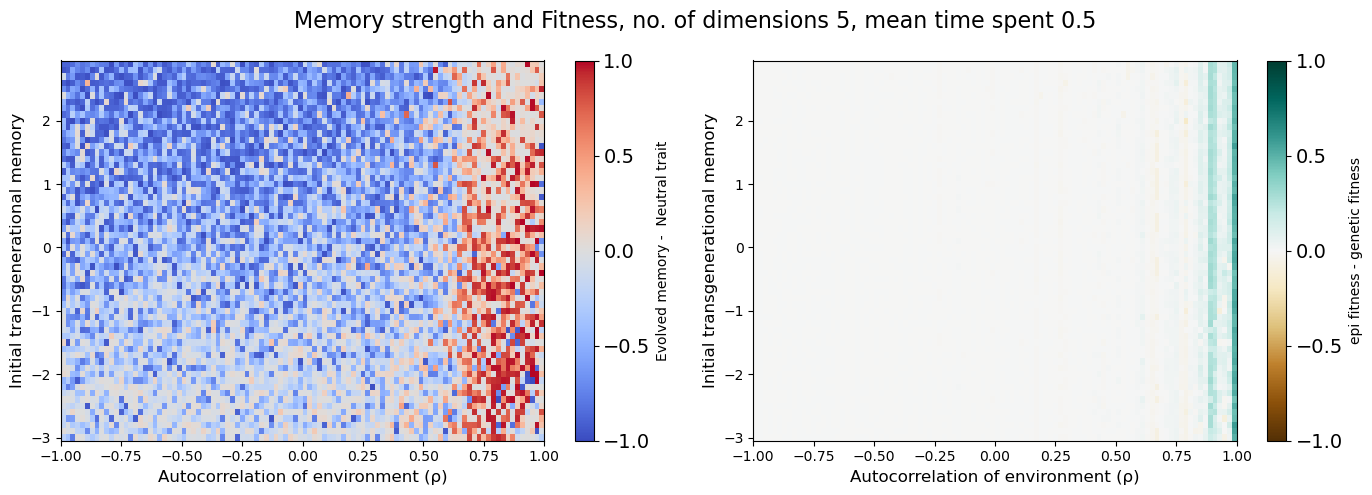

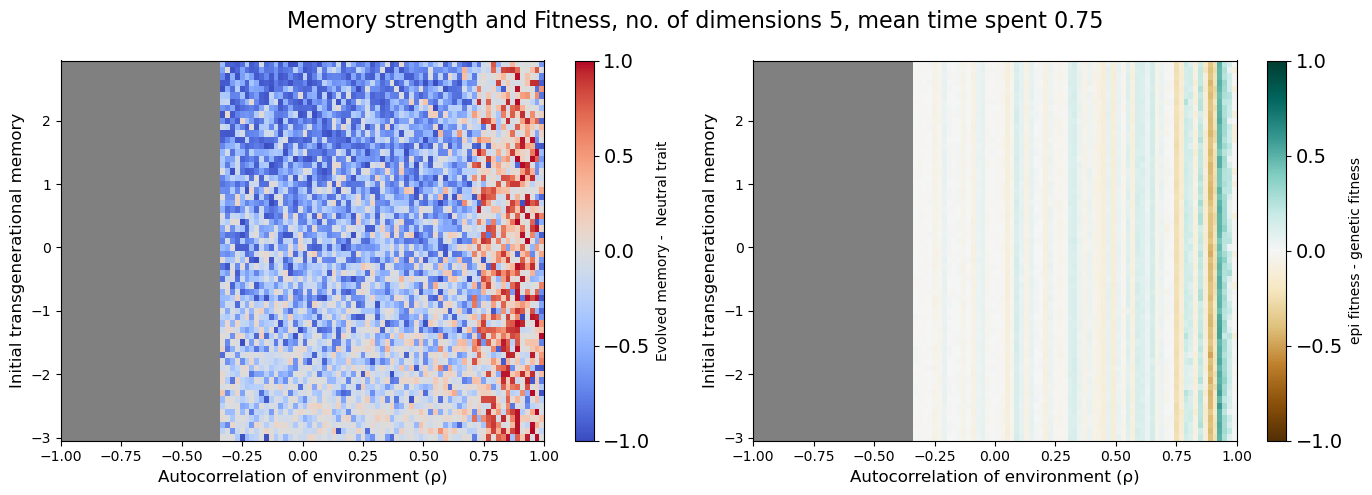

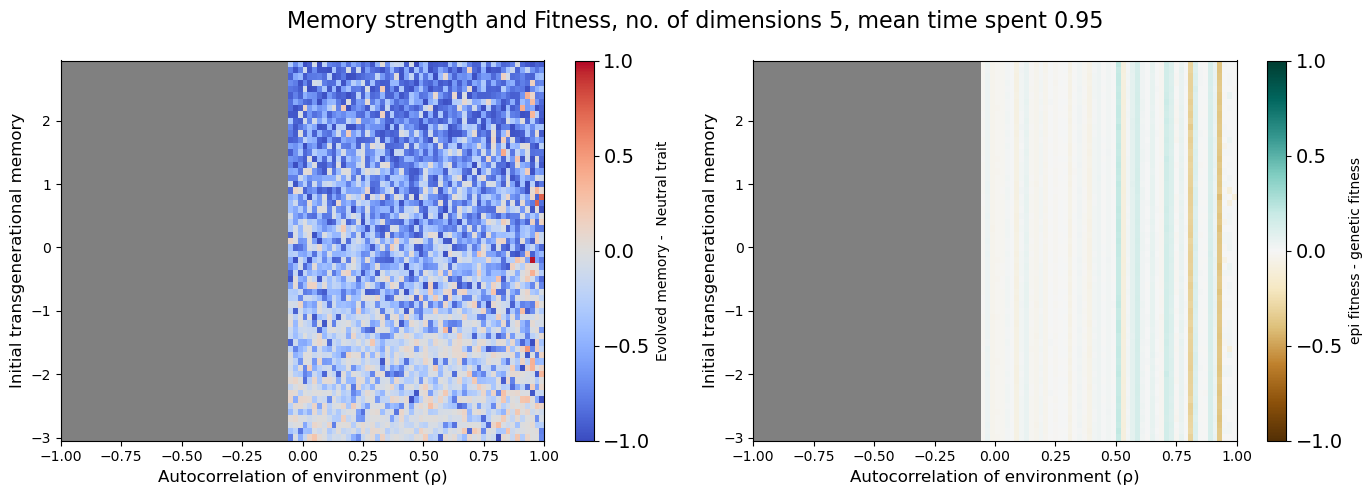

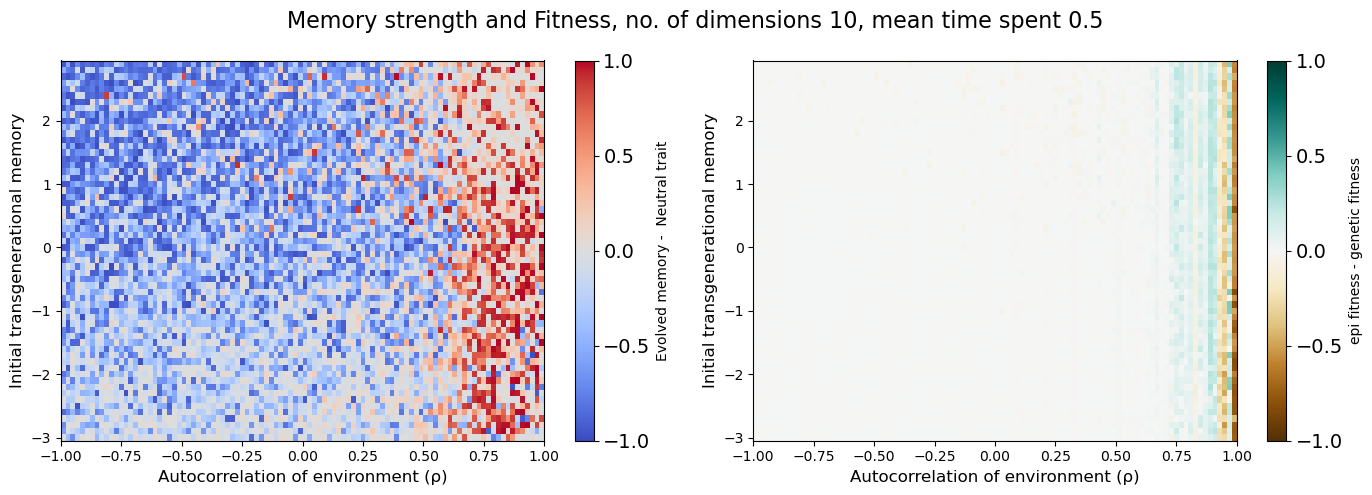

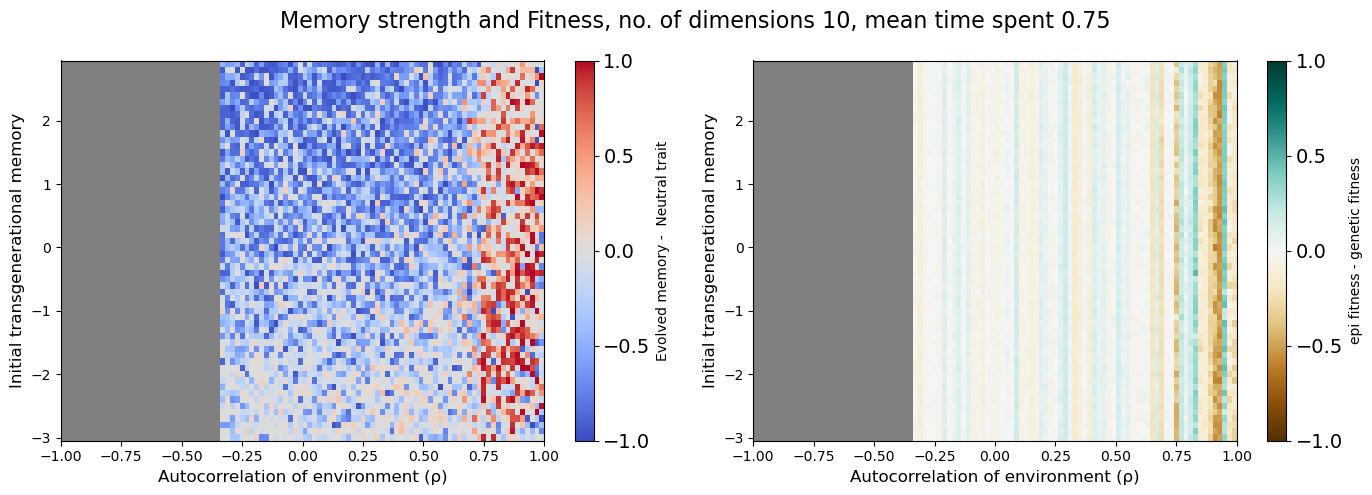

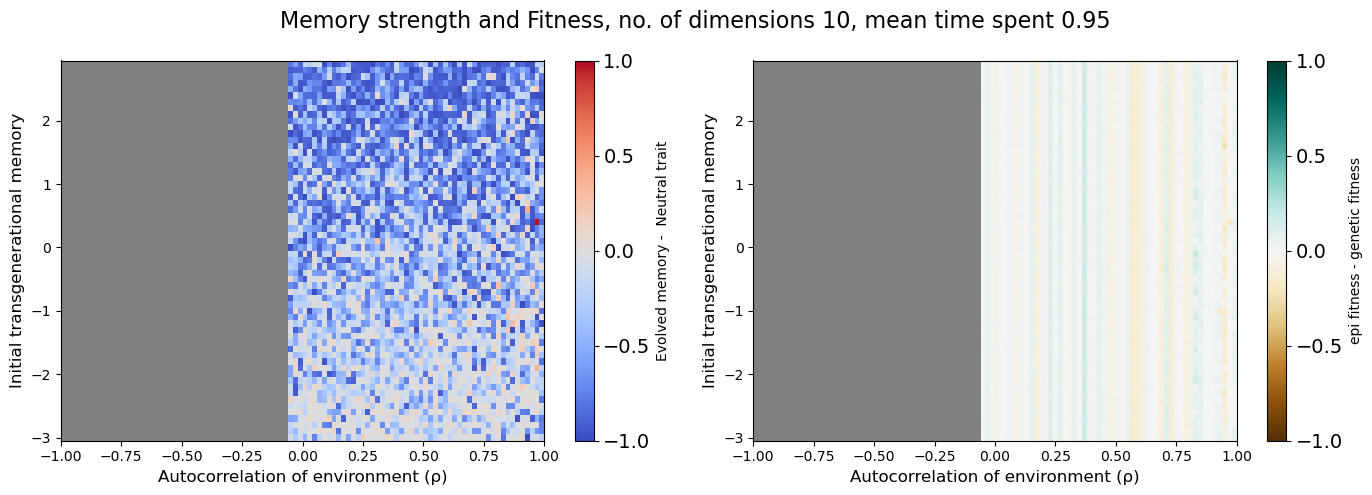

In [21]:


# Normalize rho range → [0, 1]

norm_rho = mcolors.Normalize(vmin=-1, vmax=1)
norm_m = mcolors.Normalize(vmin=0.5, vmax=1)
cmap_rho = cm.get_cmap("spring")
cmap_m = cm.get_cmap("cividis")


# Create figure once (outside loop)
# Loop over scenarios
for dim in dimensions:
    
    nof_dims = "_".join(dim.split("_")[1:])
    
    data_subsetdim = sp_rho_data[dim]
    
    
    for m, group in data_subsetdim.groupby("ms"):

        
        fig, ax = plt.subplots(1, 2, figsize=(14, 5))
        fig.suptitle(f"Memory strength and Fitness, no. of dimensions {nof_dims}, mean time spent {m}", fontsize=16)
        fig.subplots_adjust(top=0.90)   # more space for the suptitle
        
        # colormap for difference
        cmap1 = plt.cm.coolwarm.copy()
        cmap1.set_bad(color='gray')

        # symmetric normalization around 0
        norm_diff_1 = mcolors.TwoSlopeNorm(vmin=-1, vcenter=0.0, vmax=1)
        
        # colormap for difference
        cmap2 = plt.cm.BrBG.copy()
        cmap2.set_bad(color='gray')

        # symmetric normalization around 0
        norm_diff_2 = mcolors.TwoSlopeNorm(vmin=-1, vcenter=0.0, vmax=1)
        
        
        data = pd.merge(
                scenarios,
                group,
                on=['rhos', 'initial_mem'],
                how='left')
        
        data['initial_mem_p'] = 1 / (1 + np.exp(-data['initial_mem']))
        
        data['memory_neutral_difference'] = (data['mean_last_50_mean_memory']- data['mean_last_50_mean_neutral'])
        
        data['memory_genetic_difference'] = (data['mean_last_50_epi_fitness'] - data['mean_last_50_genetic_fitness'])
        
            # --- (1,0) epimem ---
        pivoted_epi = data.pivot(
                index='initial_mem',
                columns='rhos',
                values='memory_neutral_difference'
            ).sort_index().sort_index(axis=1)

        pcm3 = ax[0].pcolormesh(
                pivoted_epi.columns,
                pivoted_epi.index,
                pivoted_epi.values,
                cmap=cmap1,
                norm=norm_diff_1,
                shading='auto'
            )
        cbar3 = fig.colorbar(pcm3, ax=ax[0], label=r'Evolved memory -  Neutral trait',
                               ticks=[-1, -0.5, 0, 0.5, 1.0])
        cbar3.ax.tick_params(labelsize=14)

        ax[0].set_ylabel('mean time spent in environment A (m)', fontsize=12)
        #ax[1,0].set_xlim(0,1)
        ax[0].set_ylabel('Initial transgenerational memory', fontsize=12)
        ax[0].set_xlabel('Autocorrelation of environment (ρ)', fontsize=12)

            # --- (1,1) neutral ---
        pivoted_neutral = data.pivot(
                index='initial_mem',
                columns='rhos',
                values='memory_genetic_difference'
            ).sort_index().sort_index(axis=1)

        pcm4 = ax[1].pcolormesh(
                pivoted_neutral.columns,
                pivoted_neutral.index,
                pivoted_neutral.values,
                cmap=cmap2,
                norm=norm_diff_2,
                shading='auto'
            )
        cbar4 = fig.colorbar(pcm4, ax=ax[1], label='epi fitness - genetic fitness',
                                ticks=[-1, -0.5, 0, 0.5, 1.0])
        cbar4.ax.tick_params(labelsize=14)

        ax[1].set_ylabel('mean time spent in environment A (m)', fontsize=12)
        #ax[1,1].set_xlim(0,1)
        ax[1].set_ylabel('Initial transgenerational memory', fontsize=12)
        ax[1].set_xlabel('Autocorrelation of environment (ρ)', fontsize=12)
                
                
        folder = '/home/usriniva/Desktop/Phd/Epigenetics/Simulations/New_Hanna_eqns/Evolve_Transgenerational_memory/Figures/finegrain_sp'
        plt.tight_layout()
        plt.savefig(f'{folder}/Delta_memory_fitness_Epi-Neu_{dim}')
        plt.show()
            
        